In [ ]:
import pathlib
import re
import time
import warnings

import marimo as mo
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd
from phyloframe import legacy as pfl
import polars as pl
from scipy import stats as scipy_stats
import seaborn as sns
from teeplot import teeplot as tp
from watermark import watermark

from pylib import osf_fetch

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", message=".*experimental.*")
# Computer Modern math, e.g., for italic site class qualifiers
plt.rcParams["mathtext.fontset"] = "cm"

OSF_SLUG = "52y9x"
NUM_SITES = 16
ALPHA = 0.05
# minimum gap enforced between a node's origin time and its parent's
ORIGIN_TIME_EPSILON = 0.5
# calibration bins, per phyloframe's `alifestd_tgs_estimate_polars`
# documented example (all branches), and for leaf (pendant) branches
CALIBRATION_COLS = ["branch_length", "origin_time", "survival_duration"]
LEAF_CALIBRATION_COLS = ["branch_length", "origin_time"]
# dark, middle, and light shades per site class; plots use the middle
ETI_PALETTE = {
    "MLS": ["#004C7A", "#0072B2", "#8FC3E6"],
    "BENwg": ["#00664F", "#009E73", "#8ED6BE"],
    "DELbg": ["#9A3F00", "#D55E00", "#F2B48A"],
    "neutral": ["#6E6E6E", "#A6A6A6", "#DADADA"],
}

In [ ]:
def gap_points(*artists):
    """Draw point-plot markers as gaps in their connecting lines, layered as:
    connecting line, white gap, error bar, white halo, then a small dot
    marking each position."""
    for artist in artists:
        if artist is None:
            continue
        for line in [*artist.get_lines()]:
            if line.get_marker() in ("None", None, ""):
                line.set_zorder(3)  # error bars (and reference lines)
                continue
            _is_axes = hasattr(artist, "plot")
            if not _is_axes:
                # legend entries: just a dot
                line.set_linestyle("none")
                line.set_markerfacecolor(line.get_color())
                line.set_markersize(7)
                line.set_markeredgewidth(0)
                continue
            # connecting line below a white gap
            line.set_zorder(1)
            if not len(line.get_xdata()):
                continue
            _xy = line.get_xdata(), line.get_ydata()
            artist.plot(
                *_xy,
                linestyle="none",
                marker="o",
                markersize=9,
                markeredgewidth=0,
                color="white",
                zorder=2,
            )
            line.set_marker("None")
            # white halo, then small dot, above the error bar
            for _size, _color, _z in (
                (3.6, "white", 4),
                (2.2, line.get_color(), 5),
            ):
                artist.plot(
                    *_xy,
                    linestyle="none",
                    marker="o",
                    markersize=_size,
                    markeredgewidth=0,
                    color=_color,
                    zorder=_z,
                )

In [ ]:
def effect_pct(effect):
    """Express an effect size as a percent label, passing "neu" through."""
    return (
        effect
        if effect in ("neu", "neutral")
        else f"{float(effect) * 100:.1f}"
    )

In [ ]:
def right_legend(g):
    """Replace a FacetGrid's legend with a single-column legend to the right
    of the panels, vertically centered on them."""
    _handles = [*g.legend.legend_handles]
    _labels = [_text.get_text() for _text in g.legend.get_texts()]
    g.legend.remove()
    g._legend = None
    g.tight_layout()
    _boxes = [_ax.get_position() for _ax in g.axes.flat]
    return g.figure.legend(
        _handles,
        _labels,
        loc="center left",
        bbox_to_anchor=(
            max(_b.x1 for _b in _boxes) + 0.02,
            (min(_b.y0 for _b in _boxes) + max(_b.y1 for _b in _boxes)) / 2,
        ),
        ncol=1,
        frameon=False,
        handlelength=0.8,
        handletextpad=0.5,
        labelspacing=1.0,
    )

In [ ]:
def corner_xlabel(g, legend, text="Effect\nSize (%)"):
    """Place the x axis label at bottom right, left-aligned under the legend
    and level with the bottom of the bottom-left panel's tick labels."""
    _renderer = g.figure.canvas.get_renderer()
    _to_fig = g.figure.transFigure.inverted()
    _axes = g.axes.flat
    _ticks = [
        _t.get_window_extent(_renderer).transformed(_to_fig)
        for _t in _axes[len(_axes) - 1].get_xticklabels()
    ]
    g.figure.text(
        legend.get_window_extent(_renderer).transformed(_to_fig).x0,
        min(_b.y0 for _b in _ticks),
        text,
        ha="left",
        va="bottom",
        fontsize=plt.rcParams["axes.labelsize"],
    )

In [ ]:
def tilt_xticklabels(g):
    """Rotate x tick labels vertical, anchored right on their ticks."""
    for _a in g.axes.flat:
        plt.setp(
            _a.get_xticklabels(),
            rotation=90,
            ha="right",
            va="center",
            rotation_mode="anchor",
        )

In [ ]:
def estimator_settings():
    """Keyword arguments to `alifestd_tgs_estimate_polars`, per method and
    branch length calibration.

    Calibration follows the estimator's documented example: all-branch
    (allmdc) fits calibrate within clade size classes, against neutral gains
    in neighborhoods of joint quantile bins of branch length, origin time,
    and survival duration; pendant (pendantmdc) fits calibrate leaf branches
    by bins of branch length and origin time.
    """
    return {
        ("allmdc", "raw"): {},
        ("allmdc", "calibrated"): dict(
            calibration_compare_by_bins="joint_quantile_bin",
            calibration_compare_by_vals=[
                f"{_col}_rank" for _col in CALIBRATION_COLS
            ],
            calibration_partition_by="clade_size_geom_class",
        ),
        ("pendantmdc", "raw"): dict(episode_mask="is_leaf"),
        ("pendantmdc", "calibrated"): dict(
            episode_mask="is_leaf",
            calibration_compare_by_bins="leaf_quantile_bin",
            calibration_compare_by_vals=[
                f"{_col}_leaf_rank" for _col in LEAF_CALIBRATION_COLS
            ],
        ),
    }

In [ ]:
def mark_calibration_columns(phylo, trait_names, neutral_traits):
    """The phylogeny as a polars dataframe, with the columns
    `estimator_settings` calibrates by."""
    # roots have no branch, so are not fitted
    _is_fitted = pl.col("id") != pl.col("ancestor_id")
    _is_fitted_leaf = _is_fitted & pl.col("is_leaf")
    return (
        pl.from_pandas(
            phylo[
                ["id", "ancestor_id", "origin_time", "is_leaf", *trait_names]
            ],
        )
        .pipe(
            pfl.alifestd_mark_origin_time_delta_polars,
            mark_as="branch_length",
        )
        .pipe(
            pfl.alifestd_mark_max_descendant_origin_time_polars,
            mark_as="max_descendant_origin_time",
        )
        .with_columns(
            survival_duration=pl.col("max_descendant_origin_time")
            - pl.col("origin_time"),
        )
        .pipe(
            pfl.alifestd_mark_clade_size_geom_classes_polars,
            mark_as="clade_size_geom_class",
            min_class_weight=20,
            weight_by=neutral_traits,
        )
        .pipe(
            pfl.alifestd_mark_joint_quantile_bins_polars,
            bin_by=CALIBRATION_COLS,
            mark_as="joint_quantile_bin",
            partition_by="clade_size_geom_class",
        )
        .pipe(
            pfl.alifestd_mark_joint_quantile_bins_polars,
            bin_by=LEAF_CALIBRATION_COLS,
            mark_as="leaf_quantile_bin",
            partition_by="is_leaf",
        )
        .with_columns(
            pl.when(_is_fitted)
            .then(pl.col(CALIBRATION_COLS))
            .rank()
            .name.suffix("_rank"),
            pl.when(_is_fitted_leaf)
            .then(pl.col(LEAF_CALIBRATION_COLS))
            .rank()
            .name.suffix("_leaf_rank"),
        )
    )

In [ ]:
def fit_estimates(calibration_df, trait_names, neutral_traits):
    """Fits every trait with each method and calibration of
    `estimator_settings`; neutral traits are fit leave-one-out."""
    _candidates = [_t for _t in trait_names if _t not in neutral_traits]
    _results = []
    for (_method, _calibration), _kwargs in estimator_settings().items():
        _start = time.time()
        _fit = pfl.alifestd_tgs_estimate_polars(
            calibration_df,
            trait_transitions_candidate=_candidates,
            trait_transitions_neutral=neutral_traits,
            **_kwargs,
        )
        print(f"{_method} {_calibration}: {time.time() - _start:.0f}s")
        _results.append(
            _fit.to_pandas().assign(method=_method, calibration=_calibration),
        )
    return pd.concat(_results, ignore_index=True).rename(
        columns={
            "trait_name": "trait",
            "num_leaf_episodes": "num_leaves",
            "num_leaf_gains": "num_trait_present",
            "num_inner_episodes": "num_clades",
            "num_inner_gains": "num_clade_gains",
            "selection_coef": "selection",
            "selection_coef_lrt_naive": "selection_lrt_naive",
        },
    )

In [ ]:
def compute_fit_diagnostics(
    calibration_df, trait_names, neutral_traits, num_bins=200
):
    """Observed and expected trait gains under the calibrated allmdc fit,
    with and without survival time, recomputed from the estimator's own
    exposure episodes and calibrated episode durations.

    Returns `diagnostic_fits`, each trait's fitted gain rate and selection,
    and `fit_diagnostics`, branches grouped by trait, clade size class, and
    calibrated length (`num_bins` quantile bins per trait and class).
    """
    from phyloframe.legacy import _impl as pfl_impl
    from scipy import special

    _settings = estimator_settings()[("allmdc", "calibrated")]
    _candidates = [_t for _t in trait_names if _t not in neutral_traits]
    _names = [*_candidates, *neutral_traits]
    _neutral_ids = list(range(len(_candidates), len(_names)))
    _exposure = pfl_impl.tgs_build_exposure_df_polars(
        calibration_df,
        trait_transitions=_names,
        episode_mask=None,
        **_settings,
    )
    _weights = np.ones(len(_exposure))
    _neighborhoods = pfl_impl.tgs_select_calibration_neighborhoods(
        _exposure,
        neighborhood_fractions=(0.005, 0.01, 0.025, 0.05, 0.1, 0.25, 0.5, 1.0),
        neutral_trait_ids=_neutral_ids,
    )
    _fit_kwargs = dict(
        weights=_weights,
        num_traits=len(_names),
        neutral_trait_ids=_neutral_ids,
        calibration_neighborhoods=_neighborhoods,
        nll_coarsegrain_rtol=1e-2,
        loss_rate=0.0,
        fit_selection_coef_starts=(0.0, -0.3, -1.8),
        fit_growth_exponent_bound=600.0,
        calc_lrts=False,
        progress_wrap=lambda _x: _x,
    )
    # without survival time, the same model with every survival duration 0
    _fits = {
        "with survival time": pfl_impl.tgs_fit_traits(
            _exposure, **_fit_kwargs
        ),
        "without survival time": pfl_impl.tgs_fit_traits(
            _exposure.with_columns(survival_duration=pl.lit(0.0)),
            **_fit_kwargs,
        ),
    }
    diagnostic_fits = pd.concat(
        [
            _fit.to_pandas()
            .rename(columns={"selection_coef": "selection"})
            .assign(trait=_names, fit=_label)
            for _label, _fit in _fits.items()
        ],
        ignore_index=True,
    )
    # reference gain rate: mean over neutral sites (other neutral sites,
    # for a neutral site), from the fit with survival time
    _with = diagnostic_fits[diagnostic_fits["fit"] == "with survival time"]
    _neu_rates = _with.set_index("trait").loc[neutral_traits, "gain_rate"]
    diagnostic_fits["neutral_gain_rate"] = [
        _neu_rates.drop(_t, errors="ignore").mean()
        for _t in diagnostic_fits["trait"]
    ]

    # clade size classes (calibration partitions), labeled by size range
    _partitions = _exposure["partition_id"].to_numpy()
    _clade_sizes = _exposure["clade_size"].to_numpy()
    _num_partitions = _partitions.max() + 1
    _size_lo = np.full(_num_partitions, np.iinfo(np.int64).max)
    np.minimum.at(_size_lo, _partitions, _clade_sizes)
    _size_hi = np.zeros(_num_partitions, dtype=np.int64)
    np.maximum.at(_size_hi, _partitions, _clade_sizes)
    _size_order = np.argsort(np.argsort(_size_lo))
    _labels = np.array(
        [
            f"{_lo}" if _lo == _hi else f"{_lo}–{_hi}"
            for _lo, _hi in zip(_size_lo, _size_hi)
        ],
    )

    _bin_counts = pfl_impl.tgs_count_trait_exposures_binwise(
        _exposure, trait_ids=_neutral_ids, weights=_weights
    )
    _durations = _exposure["episode_duration"].to_numpy()
    _survival = _exposure["survival_duration"].to_numpy()
    _bin_ids = _exposure["bin_id"].to_numpy()
    _diagnostics = []
    for _trait_id, _trait in enumerate(_names):
        _starts = _exposure[
            f"trait{_trait_id}_episode_starts_absent"
        ].to_numpy()
        _gained = ~_exposure[
            f"trait{_trait_id}_episode_ends_absent"
        ].to_numpy()
        _factors = pfl_impl.tgs_calc_calibration_rescaling(
            trait_bin_counts_df=_bin_counts,
            trait_id=_trait_id,
            neutral_trait_ids=_neutral_ids,
            calibration_neighborhoods=_neighborhoods,
        )
        _length = (_durations * _factors[_bin_ids])[_starts]
        _part = _partitions[_starts]
        # quantile bins of calibrated length within each size class
        _order = np.lexsort((_length, _part))
        _rank = np.empty(len(_order), dtype=np.int64)
        _rank[_order] = np.arange(len(_order))
        _part_start = np.searchsorted(_part[_order], _part)
        _part_count = np.bincount(_part, minlength=_num_partitions)[_part]
        _fine = (_rank - _part_start) * num_bins // _part_count
        _key = _part * num_bins + _fine
        _num_keys = _num_partitions * num_bins
        _columns = {
            "num_trials": np.bincount(_key, minlength=_num_keys),
            "num_successes": np.bincount(
                _key, _gained[_starts].astype(float), minlength=_num_keys
            ),
            "length": np.bincount(_key, _length, minlength=_num_keys),
        }
        for _label, _fit in _fits.items():
            _g = _fit["gain_rate"][_trait_id]
            _c = _fit["selection_coef"][_trait_id]
            if not _g > 0:
                _c = 0.0
            _effective = _length * special.exprel(
                np.minimum(_c * _length, 600.0)
            )
            _growth = np.exp(
                np.minimum(
                    _c
                    * (
                        _survival[_starts]
                        if _label == "with survival time"
                        else 0.0
                    ),
                    600.0,
                ),
            )
            _columns[f"expected {_label}"] = np.bincount(
                _key, _g * _effective * _growth, minlength=_num_keys
            )
        _df = pd.DataFrame(_columns).assign(
            trait=_trait,
            size_partition=np.repeat(_size_order, num_bins),
            clade_size=np.repeat(_labels, num_bins),
        )
        _df = _df[_df["num_trials"] > 0].copy()
        _df["length"] /= _df["num_trials"]
        _diagnostics.append(_df)
    fit_diagnostics = pd.concat(_diagnostics, ignore_index=True)
    return diagnostic_fits, fit_diagnostics

In [ ]:
mo.md(f"""
```Text
{watermark(
    current_date=True,
    iso8601=True,
    machine=True,
    updated=True,
    python=True,
    iversions=True,
    globals_=globals(),
)}
```
""")

```Text
Last updated: 2026-11-12T05:56:07.965635+00:00

Python implementation: CPython
Python version       : 3.10.22
IPython version      : 8.39.0

Compiler    : GCC 13.3.0
OS          : Linux
Release     : 7.0.0-1017-azure
Machine     : x86_64
Processor   : x86_64
CPU cores   : 4
Architecture: 64bit

phyloframe: 0.19.0
polars    : 1.36.1
matplotlib: 3.10.9
seaborn   : 0.13.2
scipy     : 1.14.1
re        : 2.2.1
pandas    : 2.2.3
teeplot   : 1.4.2
numpy     : 2.1.2
marimo    : 0.23.2

```

In [ ]:
mo.md(f"""
# MLS Individual-host Spectra, Full-grid Fossils: Trait Gain and Selection Estimates from All MDCs

Estimates per-site gain rate and net selection from mutationally defined clades (MDCs) of every size in one full-grid run, using `alifestd_tgs_estimate_polars` from [phyloframe 0.19.0](https://github.com/mmore500/phyloframe/releases/tag/v0.19.0).

Data were generated by [`wse-async-ga` `wsclust/2026-11-01-mls-indiv-spectra-fullgrid-fossils`](https://github.com/mmore500/wse-async-ga/tree/32c5351d91569ad2bbfb149150c5cc88b428dd13/wsclust/2026-11-01-mls-indiv-spectra-fullgrid-fossils) (added in [mmore500/wse-async-ga#95](https://github.com/mmore500/wse-async-ga/pull/95)) and are hosted at <https://osf.io/{OSF_SLUG}>.
That workflow repeats the full-grid (subgrid 0) configuration of `2026-10-23-mls-indiv-spectra-subgrid-fossils` with a new seed (1101).
The file is the run's hstrat-reconstructed phylogeny minified without collapsing monomorphic clades (`06-minify-nocollapse-phylo`), so every sampled fossil genome is its own leaf.
Fossils were collected by reservoir sampling, so each fossil layer spans the whole run rather than one timepoint.

Runs use genome flavor `genome_mlsindivspectra_2026_10_23`.
Each population member is a host: a clear genome is an uninfected host, and otherwise the genome is the host's (transmitted) consensus strain.
The genome carries three spectra of four sites each, with base effect sizes $s_i \\in [0.05, 0.025, 0.01, 0.005]$, plus four neutral sites:

- **MLS** sites (`MLS`) both are favored within a host and reduce transmission,
- **between-group deleterious** sites (`DELbg`) only reduce transmission, and
- **within-group beneficial** sites (`BENwg`) are only favored within a host.

Labels follow the ETI framework, with evaluation bar notation giving each trait's between-group (transmission) effect above and within-group (host) effect below, and $\\varnothing$ for no effect: MLS $|^{{-}}_{{+}}$, DELbg $|^{{-}}_{{\\varnothing}}$, BENwg $|^{{\\varnothing}}_{{+}}$, and neutral sites NEU $|^{{\\varnothing}}_{{\\varnothing}}$.

Each transmission-reducing site present blocks infection of an uninfected host with probability $s_i$ times a transmission reduction scale (0.5 here).
Each within-host-favored site is gained within a host with probability equal to the mutant fraction after 25 within-host doublings with relative growth rate $1 + s_i$ (and lost with growth rate $1 / (1 + s_i)$).
Between-host deleterious and neutral sites flip at the rate-matched $s \\to 0$ limit of the same rule.

The estimator fits every branch whose parent lacks a trait (an exposure episode) to

$$p = \\mathrm{{gain\\_rate}} \\cdot \\frac{{e^{{c \\ell}} - 1}}{{c}} \\cdot e^{{c \\tau}}, \\quad c = \\mathrm{{selection}} - \\mathrm{{loss\\_rate}},$$

where $p$ is the probability that the branch gained the trait (i.e., is an MDC stem), $\\ell$ is the branch length, and $\\tau$ is the branch's survival time, from its end node to the latest sampled leaf below it.
So, within-host advantage shows up as a raised gain rate (here, relative to neutral sites: the gain ratio), and between-host cost as negative selection: carrier lineages that must persist longer to be seen at every leaf of their clade are seen less often.
Times are in `origin_time` units (two per generation).
""")

# MLS Individual-host Spectra, Full-grid Fossils: Trait Gain and Selection Estimates from All MDCs

Estimates per-site gain rate and net selection from mutationally defined clades (MDCs) of every size in one full-grid run, using `alifestd_tgs_estimate_polars` from [phyloframe 0.19.0](https://github.com/mmore500/phyloframe/releases/tag/v0.19.0).

Data were generated by [`wse-async-ga` `wsclust/2026-11-01-mls-indiv-spectra-fullgrid-fossils`](https://github.com/mmore500/wse-async-ga/tree/32c5351d91569ad2bbfb149150c5cc88b428dd13/wsclust/2026-11-01-mls-indiv-spectra-fullgrid-fossils) (added in [mmore500/wse-async-ga#95](https://github.com/mmore500/wse-async-ga/pull/95)) and are hosted at <https://osf.io/52y9x>.
That workflow repeats the full-grid (subgrid 0) configuration of `2026-10-23-mls-indiv-spectra-subgrid-fossils` with a new seed (1101).
The file is the run's hstrat-reconstructed phylogeny minified without collapsing monomorphic clades (`06-minify-nocollapse-phylo`), so every sampled fossil genome is its own leaf.
Fossils were collected by reservoir sampling, so each fossil layer spans the whole run rather than one timepoint.

Runs use genome flavor `genome_mlsindivspectra_2026_10_23`.
Each population member is a host: a clear genome is an uninfected host, and otherwise the genome is the host's (transmitted) consensus strain.
The genome carries three spectra of four sites each, with base effect sizes $s_i \in [0.05, 0.025, 0.01, 0.005]$, plus four neutral sites:

- **MLS** sites (`MLS`) both are favored within a host and reduce transmission,
- **between-group deleterious** sites (`DELbg`) only reduce transmission, and
- **within-group beneficial** sites (`BENwg`) are only favored within a host.

Labels follow the ETI framework, with evaluation bar notation giving each trait's between-group (transmission) effect above and within-group (host) effect below, and $\varnothing$ for no effect: MLS $|^{-}_{+}$, DELbg $|^{-}_{\varnothing}$, BENwg $|^{\varnothing}_{+}$, and neutral sites NEU $|^{\varnothing}_{\varnothing}$.

Each transmission-reducing site present blocks infection of an uninfected host with probability $s_i$ times a transmission reduction scale (0.5 here).
Each within-host-favored site is gained within a host with probability equal to the mutant fraction after 25 within-host doublings with relative growth rate $1 + s_i$ (and lost with growth rate $1 / (1 + s_i)$).
Between-host deleterious and neutral sites flip at the rate-matched $s \to 0$ limit of the same rule.

The estimator fits every branch whose parent lacks a trait (an exposure episode) to

$$p = \mathrm{gain\_rate} \cdot \frac{e^{c \ell} - 1}{c} \cdot e^{c \tau}, \quad c = \mathrm{selection} - \mathrm{loss\_rate},$$

where $p$ is the probability that the branch gained the trait (i.e., is an MDC stem), $\ell$ is the branch length, and $\tau$ is the branch's survival time, from its end node to the latest sampled leaf below it.
So, within-host advantage shows up as a raised gain rate (here, relative to neutral sites: the gain ratio), and between-host cost as negative selection: carrier lineages that must persist longer to be seen at every leaf of their clade are seen less often.
Times are in `origin_time` units (two per generation).

## Get Data

In [ ]:
data_path = osf_fetch(OSF_SLUG)

downloading https://osf.io/52y9x/download -> /tmp/52y9x
size: 62662226 bytes


In [ ]:
pl.scan_parquet(data_path).collect_schema()

Schema([('origin_time', Int16), ('dstream_rank', Int16), ('dstream_S', Int16), ('hstrat_differentia_bitwidth', UInt8), ('is_extant', Boolean), ('is_genome', Boolean), ('trait_present', UInt16), ('trait_focal', UInt16), ('layer', UInt8), ('layer_T', UInt8), ('row', UInt16), ('col', UInt16), ('subgrid', UInt8), ('subgrid_row', UInt8), ('subgrid_col', UInt8), ('config', String), ('file', Categorical), ('replicate', Categorical), ('sample_per_stratum', UInt16), ('genomeFlavor', Categorical), ('populationFlavor', Categorical), ('memcpyMajor', Categorical), ('globalSeed', UInt16), ('nCol', UInt16), ('nRow', UInt16), ('nWav', UInt8), ('nTrait', UInt8), ('nCycle', UInt16), ('nColSubgrid', UInt8), ('nRowSubgrid', UInt8), ('nonBlock', Boolean), ('tilePopSize', UInt16), ('tournSize', Float32), ('msec', Float32), ('tsc', UInt8), ('dstream_algo', Categorical), ('dstream_storage_bitoffset', UInt8), ('dstream_storage_bitwidth', UInt8), ('dstream_T_bitoffset', UInt8), ('dstream_T_bitwidth', UInt8), ('dstream_S_right', UInt8), ('flag_site_bitwidth', UInt8), ('flag_sites_bitoffset', UInt8), ('flag_sites_bitwidth', UInt8), ('mls_transmission_reduction_p_byte1_bit0', Float32), ('mls_withinhost_gain_p_byte1_bit0', Float32), ('mls_withinhost_loss_p_byte1_bit0', Float32), ('mls_transmission_reduction_p_byte1_bit1', Float32), ('mls_withinhost_gain_p_byte1_bit1', Float32), ('mls_withinhost_loss_p_byte1_bit1', Float32), ('mls_transmission_reduction_p_byte1_bit2', Float32), ('mls_withinhost_gain_p_byte1_bit2', Float32), ('mls_withinhost_loss_p_byte1_bit2', Float32), ('mls_transmission_reduction_p_byte1_bit3', Float32), ('mls_withinhost_gain_p_byte1_bit3', Float32), ('mls_withinhost_loss_p_byte1_bit3', Float32), ('deleterious_transmission_reduction_p_byte1_bit4', Float32), ('deleterious_withinhost_gain_p_byte1_bit4', Float32), ('deleterious_withinhost_loss_p_byte1_bit4', Float32), ('deleterious_transmission_reduction_p_byte1_bit5', Float32), ('deleterious_withinhost_gain_p_byte1_bit5', Float32), ('deleterious_withinhost_loss_p_byte1_bit5', Float32), ('deleterious_transmission_reduction_p_byte1_bit6', Float32), ('deleterious_withinhost_gain_p_byte1_bit6', Float32), ('deleterious_withinhost_loss_p_byte1_bit6', Float32), ('deleterious_transmission_reduction_p_byte1_bit7', Float32), ('deleterious_withinhost_gain_p_byte1_bit7', Float32), ('deleterious_withinhost_loss_p_byte1_bit7', Float32), ('beneficial_transmission_reduction_p_byte0_bit0', Float32), ('beneficial_withinhost_gain_p_byte0_bit0', Float32), ('beneficial_withinhost_loss_p_byte0_bit0', Float32), ('beneficial_transmission_reduction_p_byte0_bit1', Float32), ('beneficial_withinhost_gain_p_byte0_bit1', Float32), ('beneficial_withinhost_loss_p_byte0_bit1', Float32), ('beneficial_transmission_reduction_p_byte0_bit2', Float32), ('beneficial_withinhost_gain_p_byte0_bit2', Float32), ('beneficial_withinhost_loss_p_byte0_bit2', Float32), ('beneficial_transmission_reduction_p_byte0_bit3', Float32), ('beneficial_withinhost_gain_p_byte0_bit3', Float32), ('beneficial_withinhost_loss_p_byte0_bit3', Float32), ('mls_host_clear_p', Float32), ('mls_withinhost_neutral_p', Float32), ('_compconf_dummy', UInt8), ('CEREBRASLIB_TRAITLOGGER_NUM_BITS', UInt8), ('CEREBRASLIB_NONZERO_FIT_FUDGE', Float32), ('CEREBRASLIB_POPULATION_EXTINCTION_PROBABILITY', Float32), ('CEREBRASLIB_MLS_TRANSMISSION_REDUCTION_SCALE', Float32), ('CEREBRASLIB_MLS_WITHINHOST_DOUBLINGS', Float32), ('CEREBRASLIB_TRAITLOGGER_DILATION', UInt8), ('CEREBRASLIB_TRAITLOGGER_DSTREAM_ALGO_NAME', Categorical), ('CEREBRASLIB_HSTRAT_T_DILATION', UInt8), ('CEREBRASLIB_HSTRAT_DSTREAM_ALGO_NAME', Categorical), ('CEREBRASLIB_MLS_LOG10_NEUTRAL_MUTATION_RATE', Float32), ('CEREBRASLIB_MLS_HOST_CLEAR_P', Float32), ('ASYNC_GA_FOSSIL_SAMPLING_MODE', Categorical), ('ASYNC_GA_GENOME_FLAVOR', Categorical), ('ASYNC_GA_POPULATION_FLAVOR', Categorical), ('ASYNC_GA_POPSIZE', UInt16), ('clade_size', UInt8), ('last_origin_time', Int16), ('ancestor_offset', Int16)])

In [ ]:
def _config_cols(names):
    return [
        name
        for name in names
        if name.startswith(("ASYNC_GA_", "CEREBRASLIB_", "dstream_algo"))
        or re.match(r"^(mls|deleterious|beneficial)_", name)
        or name
        in (
            "config",
            "genomeFlavor",
            "populationFlavor",
            "globalSeed",
            "nCol",
            "nRow",
            "nColSubgrid",
            "nRowSubgrid",
            "nWav",
            "nTrait",
            "nCycle",
            "tilePopSize",
            "tournSize",
            "replicate",
            "trait_focal",
            "dstream_S",
            "hstrat_differentia_bitwidth",
            "sample_per_stratum",
        )
    ]

_lazy = pl.scan_parquet(data_path).filter(pl.col("clade_size") > 0)
# the file holds one run; check before taking its first row
assert _lazy.select(pl.col("config").n_unique()).collect().item() == 1
config_df = (
    _lazy.select(_config_cols(_lazy.collect_schema().names()))
    .head(1)
    .collect()
)
assert config_df["nColSubgrid"].item() == 0, "expected full grid"
config_df.transpose(include_header=True)

column,column_0
str,str
"""dstream_S""","""128"""
"""hstrat_differentia_bitwidth""","""1"""
"""trait_focal""","""65295"""
"""config""","""flavor=genome_mlsindivspectra_…"
"""replicate""","""5b332a38-5f88-40eb-8ec3-2cf207…"
…,…
"""CEREBRASLIB_MLS_HOST_CLEAR_P""","""0.1"""
"""ASYNC_GA_FOSSIL_SAMPLING_MODE""","""reservoir"""
"""ASYNC_GA_GENOME_FLAVOR""","""genome_mlsindivspectra_2026_10…"


In [ ]:
# site class K's level-i site is flag byte B, bit b (trait site 8B + b),
# with transmission reduction (0 where a class lacks it) and within-host
# gain and loss probabilities
_config = config_df.row(0, named=True)
_site_cols = [
    (int(B) * 8 + int(b), kind, what, col)
    for col in config_df.columns
    for kind, what, B, b in re.findall(
        r"^(mls|deleterious|beneficial)"
        r"_(transmission_reduction|withinhost_gain|withinhost_loss)"
        r"_p_byte(\d+)_bit(\d+)$",
        col,
    )
]
effect_sizes = (
    pd.DataFrame(
        [
            {"site": site, "kind": kind, f"{what}_p": _config[col]}
            for site, kind, what, col in _site_cols
        ],
    )
    .groupby("site", as_index=False)
    .first()
)
_txscale = _config["CEREBRASLIB_MLS_TRANSMISSION_REDUCTION_SCALE"]
_neutral_p = _config["mls_withinhost_neutral_p"]
# base effect size s_i is transmission reduction over its scale; within-
# host beneficial sites have none, so take s_i from the MLS site with the
# same within-host gain probability
effect_sizes["effect_size"] = (
    effect_sizes["transmission_reduction_p"] / _txscale
).round(6)
_is_mls = effect_sizes["kind"] == "mls"
_gain_to_s = dict(
    zip(
        effect_sizes.loc[_is_mls, "withinhost_gain_p"],
        effect_sizes.loc[_is_mls, "effect_size"],
    ),
)
_is_ben = effect_sizes["kind"] == "beneficial"
effect_sizes.loc[_is_ben, "effect_size"] = effect_sizes.loc[
    _is_ben, "withinhost_gain_p"
].map(_gain_to_s)
assert effect_sizes["effect_size"].notna().all()
# configured within-host gain probability relative to neutral sites'
effect_sizes["configured_gain_ratio"] = (
    effect_sizes["withinhost_gain_p"] / _neutral_p
)
focal_sites = sorted(effect_sizes["site"].unique().tolist())
_focal_mask = sum(1 << site for site in focal_sites)
assert config_df["trait_focal"].item() == _focal_mask, "focal mismatch"
neutral_sites = [
    site for site in range(NUM_SITES) if site not in focal_sites
]

# ETI evaluation bar notation: between-group effect above, within-group
# effect below, with null (crossed circle) for no effect
kind_labels = {
    "MLS": r"MLS$|^{-}_{+}$",
    "DELbg": r"DEL$\mathit{bg}|^{-}_{\varnothing}$",
    "BENwg": r"BEN$\mathit{wg}|^{\varnothing}_{+}$",
    "NEU": r"NEU$|^{\varnothing}_{\varnothing}$",
}
_kind_of = {
    "mls": kind_labels["MLS"],
    "deleterious": kind_labels["DELbg"],
    "beneficial": kind_labels["BENwg"],
}
_info = effect_sizes.set_index("site")
site_info = pd.DataFrame(
    {
        "site": range(NUM_SITES),
        "trait": [f"site{site}" for site in range(NUM_SITES)],
        "kind": [
            (
                _kind_of[_info.loc[site, "kind"]]
                if site in focal_sites
                else kind_labels["NEU"]
            )
            for site in range(NUM_SITES)
        ],
        "effect_size": [
            (
                effect_pct(_info.loc[site, "effect_size"])
                if site in focal_sites
                else "neu"
            )
            for site in range(NUM_SITES)
        ],
        "configured_gain_ratio": [
            (
                _info.loc[site, "configured_gain_ratio"]
                if site in focal_sites
                else 1.0
            )
            for site in range(NUM_SITES)
        ],
    },
)
kind_order = [
    kind_labels[_kind] for _kind in ("NEU", "BENwg", "DELbg", "MLS")
]
kind_palette = {
    kind_labels[_kind]: ETI_PALETTE[_key][1]
    for _kind, _key in (
        ("NEU", "neutral"),
        ("BENwg", "BENwg"),
        ("DELbg", "DELbg"),
        ("MLS", "MLS"),
    )
}
effect_size_order = ["neu"] + sorted(
    set(site_info["effect_size"]) - {"neu"}, key=float
)
mo.vstack([effect_sizes, site_info])

,site,kind,transmission_reduction_p,withinhost_gain_p,withinhost_loss_p,effect_size,configured_gain_ratio
0,0,beneficial,0.0000,1.992270e-06,5.845754e-07,0.050,1.992272
1,1,beneficial,0.0000,1.389192e-06,7.486867e-07,0.025,1.389193
2,2,beneficial,0.0000,1.136100e-06,8.858464e-07,0.010,1.136102
3,3,beneficial,0.0000,1.065186e-06,9.403101e-07,0.005,1.065188
4,8,mls,0.0250,1.992270e-06,5.845754e-07,0.050,1.992272
...,...,...,...,...,...,...,...
7,11,mls,0.0025,1.065186e-06,9.403101e-07,0.005,1.065188
8,12,deleterious,0.0250,9.999990e-07,9.999990e-07,0.050,1.000000
9,13,deleterious,0.0125,9.999990e-07,9.999990e-07,0.025,1.000000
10,14,deleterious,0.0050,9.999990e-07,9.999990e-07,0.010,1.000000


In [ ]:
mo.md(f"""
## Prep Data

Fossil layer 0 samples the initial population, at `origin_time == -1` before any lineage history accumulated, so these genomes are dropped.
Some roots have no `origin_time`; as roots can be no later than the run start, it is set to -1.
Lineages without retained leaves are pruned and unifurcations collapsed.

Reconstructed inner nodes can share their origin time with a child (zero-length branches), which the estimator does not allow, so each node's origin time is raised to at least its parent's plus {ORIGIN_TIME_EPSILON}.
""")

## Prep Data

Fossil layer 0 samples the initial population, at `origin_time == -1` before any lineage history accumulated, so these genomes are dropped.
Some roots have no `origin_time`; as roots can be no later than the run start, it is set to -1.
Lineages without retained leaves are pruned and unifurcations collapsed.

Reconstructed inner nodes can share their origin time with a child (zero-length branches), which the estimator does not allow, so each node's origin time is raised to at least its parent's plus 0.5.

In [ ]:
# unminify: rows are in depth-first order, with id = row index
_raw = (
    pl.read_parquet(
        data_path,
        columns=[
            "ancestor_offset",
            "origin_time",
            "clade_size",
            "trait_present",
            "layer",
            "row",
            "col",
        ],
    )
    .with_row_index("id")
    .with_columns(
        pl.col("id").cast(pl.Int64),
        ancestor_id=(
            pl.col("id").cast(pl.Int64)
            - pl.col("ancestor_offset").cast(pl.Int64)
        ),
        trait_present=pl.col("trait_present").cast(pl.Int64),
        row=pl.col("row").cast(pl.Int64),
        col=pl.col("col").cast(pl.Int64),
        layer=pl.col("layer").cast(pl.Int64),
    )
    .drop("ancestor_offset")
    .to_pandas()
)
raw_num_nodes = len(_raw)
# no-collapse minification: every genome is a leaf of its own
_is_genome = _raw["clade_size"] > 0
assert (_raw.loc[_is_genome, "clade_size"] == 1).all()
assert (_is_genome == _raw["trait_present"].notna()).all()
# some roots lack origin_time; roots can be no later than run start
_no_time = _raw["origin_time"].isna()
assert (
    _raw.loc[_no_time, "ancestor_id"] == _raw.loc[_no_time, "id"]
).all()
_raw["origin_time"] = _raw["origin_time"].fillna(-1).astype(float)
assert (_raw["ancestor_id"] <= _raw["id"]).all()
_has_child = np.zeros(len(_raw), dtype=bool)
_has_child[_raw["ancestor_id"]] = True
_has_child[_raw["ancestor_id"] == _raw["id"]] = False
assert not (_has_child & _is_genome).any()
raw_layer_counts = (
    _raw[_is_genome]
    .groupby("layer")
    .agg(
        num_genomes=("id", "size"),
        origin_time_min=("origin_time", "min"),
        origin_time_max=("origin_time", "max"),
    )
)

phylo = (
    _raw.drop(columns=["clade_size"])
    .assign(extant=_is_genome & (_raw["origin_time"] >= 0))
    .pipe(pfl.alifestd_to_working_format, mutate=True)
    .pipe(pfl.alifestd_prune_extinct_lineages_asexual, mutate=True)
    .pipe(pfl.alifestd_collapse_unifurcations, mutate=True)
    .pipe(pfl.alifestd_to_working_format, mutate=True)
    .pipe(pfl.alifestd_mark_leaves, mutate=True)
    .reset_index(drop=True)
)
del _raw
assert (phylo["is_leaf"] == phylo["extant"]).all()
phylo = phylo.drop(columns=["extant"])
assert (phylo["id"] == np.arange(len(phylo))).all()

# enforce positive branch lengths
_anc = phylo["ancestor_id"].to_numpy()
_is_root = _anc == phylo["id"].to_numpy()
_before = phylo["origin_time"].to_numpy().copy()
phylo = pfl.alifestd_coerce_chronological_consistency(
    phylo, mutate=True, epsilon=ORIGIN_TIME_EPSILON
)
_after = phylo["origin_time"].to_numpy()
assert (phylo.loc[phylo["is_leaf"], "origin_time"] >= 0).all()
coerce_summary = pd.Series(
    {
        "num_nodes_raw": raw_num_nodes,
        "num_nodes": len(phylo),
        "num_leaves": int(phylo["is_leaf"].sum()),
        "num_inner": int((~phylo["is_leaf"]).sum()),
        "num_roots": int(_is_root.sum()),
        "num_leaf_roots": int((_is_root & phylo["is_leaf"]).sum()),
        "num_nonpositive_branches_before": int(
            (~_is_root & (_before - _before[_anc] <= 0)).sum()
        ),
        "num_origin_times_raised": int((_after != _before).sum()),
        "num_leaf_origin_times_raised": int(
            ((_after != _before) & phylo["is_leaf"].to_numpy()).sum()
        ),
        "max_origin_time_raise": float((_after - _before).max()),
    },
)
phylo.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7854940 entries, 0 to 7854939
Data columns (total 8 columns):
 #   Column         Dtype  
---  ------         -----  
 0   id             int64  
 1   origin_time    float64
 2   trait_present  float64
 3   layer          float64
 4   row            float64
 5   col            float64
 6   ancestor_id    int64  
 7   is_leaf        bool   
dtypes: bool(1), float64(5), int64(2)
memory usage: 486.9 MB


In [ ]:
mo.Html(raw_layer_counts.to_html())

,num_genomes,origin_time_min,origin_time_max
layer,,,
0.0,59701,-1.0,-1.0
1.0,59701,1.0,131.0
2.0,59701,111.0,253.0
3.0,59701,237.0,373.0
4.0,59701,353.0,493.0
5.0,59701,479.0,615.0
6.0,59701,599.0,733.0
7.0,59701,711.0,853.0
8.0,59701,831.0,971.0


In [ ]:
coerce_summary

,0
num_nodes_raw,7914805.0
num_nodes,7854940.0
num_leaves,3940266.0
num_inner,3914674.0
num_roots,219492.0
num_leaf_roots,0.0
num_nonpositive_branches_before,1906.0
num_origin_times_raised,1906.0
num_leaf_origin_times_raised,1906.0
max_origin_time_raise,0.5


### Forest Structure

hstrat reconstruction leaves unrelated lineages unjoined, so the tree is a forest.
The estimator only uses branches below roots, so a trait carried by every leaf of a root's subtree contributes no observed gain.

In [ ]:
phylo["num_leaves"] = phylo.pipe(
    pfl.alifestd_mark_num_leaves_asexual, mutate=True
)["num_leaves"]
phylo["max_descendant_origin_time"] = phylo.pipe(
    pfl.alifestd_mark_max_descendant_origin_time_asexual, mutate=True
)["max_descendant_origin_time"]
_anc = phylo["ancestor_id"].to_numpy()
_ot = phylo["origin_time"].to_numpy()
phylo["is_root"] = _anc == phylo["id"].to_numpy()
phylo["branch_length"] = np.where(
    phylo["is_root"], np.nan, _ot - _ot[_anc]
)
phylo["survival_time"] = phylo["max_descendant_origin_time"] - _ot
_roots = phylo[phylo["is_root"]]
_root_summary = (
    _roots["num_leaves"]
    .describe(percentiles=[0.5, 0.9, 0.99, 0.999])
    .to_frame("root_num_leaves")
)
# share of leaves under the largest root subtrees
_sizes = np.sort(_roots["num_leaves"].to_numpy())[::-1]
_root_share = pd.Series(
    {
        f"top {k} roots": _sizes[:k].sum() / _sizes.sum()
        for k in (1, 10, 100, 1000)
    },
    name="leaf share",
)
mo.vstack([_root_summary, _root_share])

,root_num_leaves
count,219492.000000
mean,17.951752
std,21.619024
min,1.000000
50%,10.000000
90%,47.000000
99%,96.000000
99.9%,144.000000
max,244.000000
,leaf share


teeplots/2026-11-01-mls-indiv-spectra-fullgrid-fossils/color=6e6e6e+viz=ecdfplot+what=root-num-leaves+x=num-leaves+ext=.pdf
teeplots/2026-11-01-mls-indiv-spectra-fullgrid-fossils/color=6e6e6e+viz=ecdfplot+what=root-num-leaves+x=num-leaves+ext=.png


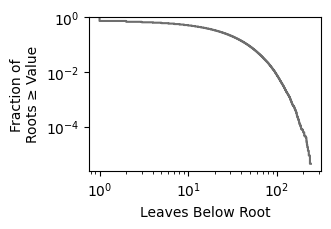

In [ ]:
with tp.teed(
    sns.ecdfplot,
    data=phylo.loc[phylo["is_root"], ["num_leaves"]],
    x="num_leaves",
    complementary=True,
    log_scale=(True, True),
    color=ETI_PALETTE["neutral"][0],
    teeplot_outattrs={"what": "root-num-leaves"},
    teeplot_show=True,
    teeplot_subdir=pathlib.Path(__file__).stem,
) as _ax:
    _ax.figure.set_size_inches(3, 2)
    _ax.set_xlabel("Leaves Below Root")
    _ax.set_ylabel("Fraction of\nRoots ≥ Value")
plt.close("all")

## Trait States and MDCs

Under parsimony without loss, a node has a trait if and only if every leaf of its clade does.
An MDC is a maximal clade whose leaves all carry the trait, which gained it on its stem branch.
Each branch whose parent lacks the trait is exposed to gaining it.
Roots are the reconstruction's placeholder ancestors at the run start, so never carry a trait: a trait carried by every leaf below a root was gained on the branch(es) below it.

In [ ]:
_is_leaf = phylo["is_leaf"].to_numpy()
_anc = phylo["ancestor_id"].to_numpy()
_is_root = phylo["is_root"].to_numpy()
_num_leaves = phylo["num_leaves"].to_numpy()
_present = phylo["trait_present"].fillna(0).to_numpy(dtype=np.int64)
trait_names = []
for _site in range(NUM_SITES):
    _has = _is_leaf & (((_present >> _site) & 1) != 0)
    _count = (
        phylo[["id", "ancestor_id"]]
        .copy()
        .pipe(
            pfl.alifestd_calc_clade_trait_count_asexual,
            mutate=True,
            trait_mask=_has,
        )
    )
    _state = (_count == _num_leaves).astype(np.int8)
    # roots are the reconstruction's placeholder ancestors, at the run
    # start, so never carry a trait: a trait carried by every leaf below
    # a root was gained on the branch(es) below it
    _state[_is_root] = 0
    # transition on the branch from each node's parent
    _name = f"site{_site}"
    phylo[_name] = _state - np.where(_is_root, 0, _state[_anc])
    assert phylo[_name].isin([0, 1]).all(), "parsimony without loss"
    trait_names.append(_name)

In [ ]:
_is_leaf = phylo["is_leaf"].to_numpy()
_is_root = phylo["is_root"].to_numpy()
_present = phylo["trait_present"].fillna(0).to_numpy(dtype=np.int64)
_cols = [
    "id",
    "origin_time",
    "branch_length",
    "survival_time",
    "num_leaves",
    "is_leaf",
]
_mdcs, _rows = [], []
for _site, _name in enumerate(trait_names):
    _delta = phylo[_name].to_numpy()
    assert not ((_delta == 1) & _is_root).any()
    _gain = _delta == 1
    _mdcs.append(phylo.loc[_gain, _cols].assign(site=_site))
    _carriers = _is_leaf & (((_present >> _site) & 1) != 0)
    _rows.append(
        {
            "site": _site,
            "num_carrier_leaves": int(_carriers.sum()),
            "carrier_leaf_frac": _carriers.mean() / _is_leaf.mean(),
            "num_mdcs": int(_gain.sum()),
            "num_leaf_mdcs": int((_gain & _is_leaf).sum()),
            "num_inner_mdcs": int((_gain & ~_is_leaf).sum()),
        },
    )
mdcs = (
    pd.concat(_mdcs, ignore_index=True)
    .merge(site_info, on="site")
    .rename(columns={"origin_time": "end_time"})
)
# stem branch start, i.e., the parent's origin time
mdcs["start_time"] = mdcs["end_time"] - mdcs["branch_length"]
mdc_counts = (
    pd.DataFrame(_rows)
    .merge(site_info, on="site")
    .merge(
        mdcs.groupby("site").agg(
            mdc_size_mean=("num_leaves", "mean"),
            mdc_size_median=("num_leaves", "median"),
            mdc_size_max=("num_leaves", "max"),
            inner_mdc_size_mean=(
                "num_leaves",
                lambda x: x[x > 1].mean(),
            ),
            inner_mdc_survival_mean=(
                "survival_time",
                lambda x: x[x > 0].mean(),
            ),
            stem_length_mean=("branch_length", "mean"),
            stem_start_median=("start_time", "median"),
        ),
        on="site",
        how="left",
    )
)
mo.Html(mdc_counts.to_html(float_format="{:.4g}".format))

,site,num_carrier_leaves,carrier_leaf_frac,num_mdcs,num_leaf_mdcs,num_inner_mdcs,trait,kind,effect_size,configured_gain_ratio,mdc_size_mean,mdc_size_median,mdc_size_max,inner_mdc_size_mean,inner_mdc_survival_mean,stem_length_mean,stem_start_median
0,0,14025,0.003559,11665,9840,1825,site0,BEN$\mathit{wg}|^{\varnothing}_{+}$,5.0,1.992,1.202,1,6,2.293,2698,3021,1726
1,1,10010,0.00254,8402,7166,1236,site1,BEN$\mathit{wg}|^{\varnothing}_{+}$,2.5,1.389,1.191,1,9,2.301,2733,3049,1726
2,2,8171,0.002074,6898,5912,986,site2,BEN$\mathit{wg}|^{\varnothing}_{+}$,1.0,1.136,1.185,1,6,2.291,2678,3060,1726
3,3,8380,0.002127,6976,5916,1060,site3,BEN$\mathit{wg}|^{\varnothing}_{+}$,0.5,1.065,1.201,1,7,2.325,2785,3041,1726
4,4,8483,0.002153,7106,6040,1066,site4,NEU$|^{\varnothing}_{\varnothing}$,neu,1,1.194,1,6,2.292,2668,3060,1726
5,5,8359,0.002121,7008,5969,1039,site5,NEU$|^{\varnothing}_{\varnothing}$,neu,1,1.193,1,6,2.3,2734,3037,1726
6,6,8389,0.002129,7027,5982,1045,site6,NEU$|^{\varnothing}_{\varnothing}$,neu,1,1.194,1,8,2.303,2755,3052,1726
7,7,8301,0.002107,7048,6079,969,site7,NEU$|^{\varnothing}_{\varnothing}$,neu,1,1.178,1,6,2.293,2718,3039,1726
8,8,2586,0.0006563,2564,2544,20,site8,MLS$|^{-}_{+}$,5.0,1.992,1.009,1,3,2.1,1385,2346,1662
9,9,3251,0.0008251,3124,3004,120,site9,MLS$|^{-}_{+}$,2.5,1.389,1.041,1,4,2.058,1771,2569,1662


### MDC Diagnostics

MDC counts, sizes (leaves), durations (survival time, from the MDC's root to its latest leaf), and stem timing, by site class and effect size.
Leaf MDCs are single sampled genomes that gained a trait on their pendant branch; inner MDCs are multi-leaf clades.
In distribution plots, each panel shows one effect size's focal sites against the four neutral sites.

teeplots/2026-11-01-mls-indiv-spectra-fullgrid-fossils/col=what+hue=kind+kind=point+viz=catplot+what=mdc-counts+x=effect-size+y=count+ext=.pdf
teeplots/2026-11-01-mls-indiv-spectra-fullgrid-fossils/col=what+hue=kind+kind=point+viz=catplot+what=mdc-counts+x=effect-size+y=count+ext=.png


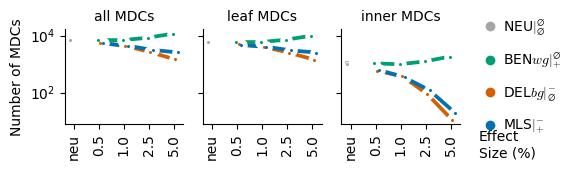

In [ ]:
_what = {
    "num_mdcs": "all",
    "num_leaf_mdcs": "leaf",
    "num_inner_mdcs": "inner",
}
_df = mdc_counts.melt(
    id_vars=["site", "kind", "effect_size"],
    value_vars=[*_what],
    var_name="what",
    value_name="count",
).assign(what=lambda df: df["what"].map(_what))
with tp.teed(
    sns.catplot,
    data=_df,
    x="effect_size",
    y="count",
    order=effect_size_order,
    hue="kind",
    hue_order=kind_order,
    palette=kind_palette,
    col="what",
    col_order=[*_what.values()],
    kind="point",
    errorbar=("pi", 100),
    dodge=0.3,
    height=1.8,
    aspect=0.9,
    log_scale=(False, True),
    teeplot_outattrs={"what": "mdc-counts"},
    teeplot_outexclude=[
        "palette",
        "hue_order",
        "col_order",
        "dodge",
        "order",
        "log_scale",
    ],
    teeplot_show=True,
    teeplot_subdir=pathlib.Path(__file__).stem,
) as _g:
    gap_points(*_g.axes.flat, _g.legend)
    _g.set_axis_labels("", "Number of MDCs")
    _g.set_titles(col_template="{col_name} MDCs")
    tilt_xticklabels(_g)
    corner_xlabel(_g, right_legend(_g))
plt.close("all")

In [ ]:
# each focal effect size's panel also shows all neutral sites
_focal_sizes = [_s for _s in effect_size_order if _s != "neu"]
mdc_panels = pd.concat(
    [
        mdcs[mdcs["effect_size"].isin([_size, "neu"])].assign(panel=_size)
        for _size in _focal_sizes
    ],
    ignore_index=True,
)

teeplots/2026-11-01-mls-indiv-spectra-fullgrid-fossils/col=panel+hue=kind+kind=ecdf+viz=displot+what=mdc-sizes+x=num-leaves+ext=.pdf
teeplots/2026-11-01-mls-indiv-spectra-fullgrid-fossils/col=panel+hue=kind+kind=ecdf+viz=displot+what=mdc-sizes+x=num-leaves+ext=.png


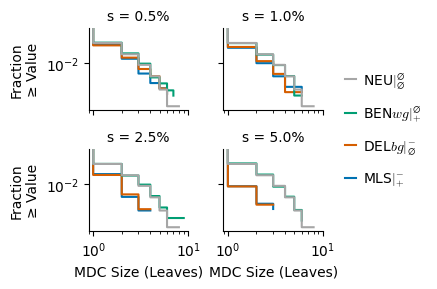

In [ ]:
with tp.teed(
    sns.displot,
    data=mdc_panels,
    x="num_leaves",
    hue="kind",
    hue_order=kind_order,
    palette=kind_palette,
    col="panel",
    col_order=[_s for _s in effect_size_order if _s != "neu"],
    col_wrap=2,
    kind="ecdf",
    complementary=True,
    log_scale=(True, True),
    height=1.5,
    aspect=1.2,
    teeplot_outattrs={"what": "mdc-sizes"},
    teeplot_outexclude=[
        "palette",
        "hue_order",
        "col_order",
        "col_wrap",
        "log_scale",
    ],
    teeplot_show=True,
    teeplot_subdir=pathlib.Path(__file__).stem,
) as _g:
    _g.set_axis_labels("MDC Size (Leaves)", "Fraction\n≥ Value")
    _g.set_titles(col_template="s = {col_name}%")
    right_legend(_g)
plt.close("all")

teeplots/2026-11-01-mls-indiv-spectra-fullgrid-fossils/col=panel+hue=kind+kind=ecdf+viz=displot+what=inner-mdc-survival+x=survival-time+ext=.pdf
teeplots/2026-11-01-mls-indiv-spectra-fullgrid-fossils/col=panel+hue=kind+kind=ecdf+viz=displot+what=inner-mdc-survival+x=survival-time+ext=.png


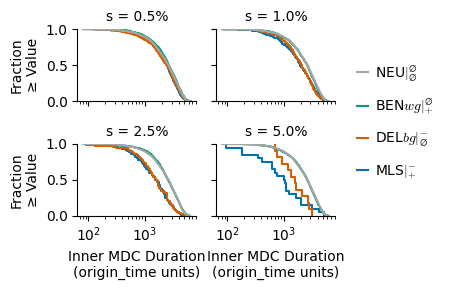

In [ ]:
# leaf MDCs have zero survival time
with tp.teed(
    sns.displot,
    data=mdc_panels[mdc_panels["survival_time"] > 0],
    x="survival_time",
    hue="kind",
    hue_order=kind_order,
    palette=kind_palette,
    col="panel",
    col_order=[_s for _s in effect_size_order if _s != "neu"],
    col_wrap=2,
    kind="ecdf",
    complementary=True,
    log_scale=(True, False),
    height=1.5,
    aspect=1.2,
    teeplot_outattrs={"what": "inner-mdc-survival"},
    teeplot_outexclude=[
        "palette",
        "hue_order",
        "col_order",
        "col_wrap",
        "log_scale",
    ],
    teeplot_show=True,
    teeplot_subdir=pathlib.Path(__file__).stem,
) as _g:
    _g.set_axis_labels(
        "Inner MDC Duration\n(origin_time units)",
        "Fraction\n≥ Value",
    )
    _g.set_titles(col_template="s = {col_name}%")
    right_legend(_g)
plt.close("all")

teeplots/2026-11-01-mls-indiv-spectra-fullgrid-fossils/col=panel+hue=kind+kind=hist+stat=density+viz=displot+what=mdc-timing+x=end-time+ext=.pdf
teeplots/2026-11-01-mls-indiv-spectra-fullgrid-fossils/col=panel+hue=kind+kind=hist+stat=density+viz=displot+what=mdc-timing+x=end-time+ext=.png


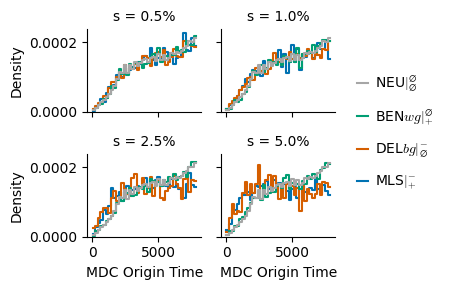

In [ ]:
with tp.teed(
    sns.displot,
    data=mdc_panels,
    x="end_time",
    hue="kind",
    hue_order=kind_order,
    palette=kind_palette,
    col="panel",
    col_order=[_s for _s in effect_size_order if _s != "neu"],
    col_wrap=2,
    kind="hist",
    stat="density",
    common_norm=False,
    element="step",
    fill=False,
    bins=40,
    height=1.5,
    aspect=1.2,
    teeplot_outattrs={"what": "mdc-timing"},
    teeplot_outexclude=[
        "palette",
        "hue_order",
        "col_order",
        "col_wrap",
        "common_norm",
        "element",
        "fill",
    ],
    teeplot_show=True,
    teeplot_subdir=pathlib.Path(__file__).stem,
) as _g:
    _g.set_axis_labels("MDC Origin Time", "Density")
    _g.set_titles(col_template="s = {col_name}%")
    right_legend(_g)
plt.close("all")

teeplots/2026-11-01-mls-indiv-spectra-fullgrid-fossils/hue=branch+kind=ecdf+viz=displot+what=branch-lengths+x=branch-length+ext=.pdf
teeplots/2026-11-01-mls-indiv-spectra-fullgrid-fossils/hue=branch+kind=ecdf+viz=displot+what=branch-lengths+x=branch-length+ext=.png


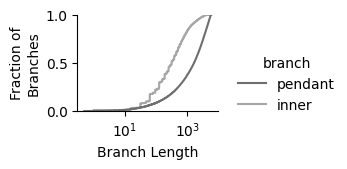

In [ ]:
_df = phylo.loc[~phylo["is_root"], ["branch_length", "is_leaf"]].assign(
    branch=lambda df: np.where(df["is_leaf"], "pendant", "inner"),
)
with tp.teed(
    sns.displot,
    data=_df,
    x="branch_length",
    hue="branch",
    hue_order=["pendant", "inner"],
    palette=[ETI_PALETTE["neutral"][0], ETI_PALETTE["neutral"][1]],
    kind="ecdf",
    log_scale=(True, False),
    height=1.8,
    aspect=1.3,
    teeplot_outattrs={"what": "branch-lengths"},
    teeplot_outexclude=["palette", "hue_order", "log_scale"],
    teeplot_show=True,
    teeplot_subdir=pathlib.Path(__file__).stem,
) as _g:
    _g.set_axis_labels("Branch Length", "Fraction of\nBranches")
plt.close("all")

In [ ]:
mo.md(f"""
### MDC Size and Duration Tests

Mann–Whitney U tests compare each site's MDC sizes (leaves) and durations (survival time, from the MDC's root to its latest leaf, 0 for leaf MDCs) against those of neutral sites' MDCs.
Each focal site is tested against all four neutral sites pooled; as a null calibration, each neutral site is tested against the other three.
Effect size is the probability that a site's MDC exceeds a reference MDC (ties count half), so 0.5 marks parity and lower values mean smaller or shorter-lived clades.
p-values are two-sided, on a log scale descending from $p = 1$ at top and clipped at $10^{{-9}}$; the dashed line marks $\\alpha = {ALPHA}$.
""")

### MDC Size and Duration Tests

Mann–Whitney U tests compare each site's MDC sizes (leaves) and durations (survival time, from the MDC's root to its latest leaf, 0 for leaf MDCs) against those of neutral sites' MDCs.
Each focal site is tested against all four neutral sites pooled; as a null calibration, each neutral site is tested against the other three.
Effect size is the probability that a site's MDC exceeds a reference MDC (ties count half), so 0.5 marks parity and lower values mean smaller or shorter-lived clades.
p-values are two-sided, on a log scale descending from $p = 1$ at top and clipped at $10^{-9}$; the dashed line marks $\alpha = 0.05$.

In [ ]:
_stats = {"num_leaves": "MDC Size", "survival_time": "MDC Duration"}
_rows = []
for _site in range(NUM_SITES):
    _focal = mdcs[mdcs["site"] == _site]
    _reference = mdcs[
        mdcs["site"].isin(neutral_sites) & (mdcs["site"] != _site)
    ]
    for _stat, _name in _stats.items():
        _x = _focal[_stat].to_numpy()
        _y = _reference[_stat].to_numpy()
        if len(_x) and len(_y):
            _res = scipy_stats.mannwhitneyu(
                _x, _y, alternative="two-sided"
            )
            _u, _p = _res.statistic, _res.pvalue
        else:
            _u, _p = np.nan, np.nan
        _rows.append(
            {
                "site": _site,
                "stat": _name,
                "num_mdcs": len(_x),
                "num_reference_mdcs": len(_y),
                "median": np.median(_x) if len(_x) else np.nan,
                "reference_median": np.median(_y) if len(_y) else np.nan,
                "mean": _x.mean() if len(_x) else np.nan,
                "reference_mean": _y.mean() if len(_y) else np.nan,
                "u_statistic": _u,
                # probability of superiority, with ties counting half
                "effect_size_ps": _u / (len(_x) * len(_y)),
                "p_value": _p,
            },
        )
mdc_tests = pd.DataFrame(_rows).merge(site_info, on="site")
mdc_tests["detected"] = mdc_tests["p_value"] < ALPHA
mo.Html(mdc_tests.to_html(float_format="{:.4g}".format))

,site,stat,num_mdcs,num_reference_mdcs,median,reference_median,mean,reference_mean,u_statistic,effect_size_ps,p_value,trait,kind,effect_size,configured_gain_ratio,detected
0,0,MDC Size,11665,28189,1,1,1.202,1.19,1.661e+08,0.5052,0.008159,site0,BEN$\mathit{wg}|^{\varnothing}_{+}$,5.0,1.992,True
1,0,MDC Duration,11665,28189,0,0,422.1,397.2,1.661e+08,0.5051,0.009826,site0,BEN$\mathit{wg}|^{\varnothing}_{+}$,5.0,1.992,True
2,1,MDC Size,8402,28189,1,1,1.191,1.19,1.185e+08,0.5004,0.8534,site1,BEN$\mathit{wg}|^{\varnothing}_{+}$,2.5,1.389,False
3,1,MDC Duration,8402,28189,0,0,402,397.2,1.186e+08,0.5006,0.8001,site1,BEN$\mathit{wg}|^{\varnothing}_{+}$,2.5,1.389,False
4,2,MDC Size,6898,28189,1,1,1.185,1.19,9.691e+07,0.4984,0.4897,site2,BEN$\mathit{wg}|^{\varnothing}_{+}$,1.0,1.136,False
5,2,MDC Duration,6898,28189,0,0,382.9,397.2,9.688e+07,0.4982,0.4599,site2,BEN$\mathit{wg}|^{\varnothing}_{+}$,1.0,1.136,False
6,3,MDC Size,6976,28189,1,1,1.201,1.19,9.894e+07,0.5031,0.1886,site3,BEN$\mathit{wg}|^{\varnothing}_{+}$,0.5,1.065,False
7,3,MDC Duration,6976,28189,0,0,423.2,397.2,9.896e+07,0.5032,0.1755,site3,BEN$\mathit{wg}|^{\varnothing}_{+}$,0.5,1.065,False
8,4,MDC Size,7106,21083,1,1,1.194,1.188,7.529e+07,0.5026,0.2882,site4,NEU$|^{\varnothing}_{\varnothing}$,neu,1,False
9,4,MDC Duration,7106,21083,0,0,400.2,396.2,7.525e+07,0.5023,0.3491,site4,NEU$|^{\varnothing}_{\varnothing}$,neu,1,False


teeplots/2026-11-01-mls-indiv-spectra-fullgrid-fossils/hue=kind+kind=point+stat=mdc-size+viz=catplot+what=mann-whitney+x=effect-size+y=effect-size-ps+ext=.pdf
teeplots/2026-11-01-mls-indiv-spectra-fullgrid-fossils/hue=kind+kind=point+stat=mdc-size+viz=catplot+what=mann-whitney+x=effect-size+y=effect-size-ps+ext=.png


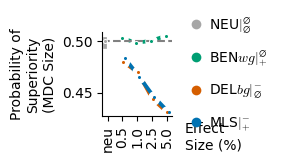

teeplots/2026-11-01-mls-indiv-spectra-fullgrid-fossils/hue=kind+kind=point+stat=mdc-size+viz=catplot+what=mann-whitney+x=effect-size+y=p-value+ext=.pdf
teeplots/2026-11-01-mls-indiv-spectra-fullgrid-fossils/hue=kind+kind=point+stat=mdc-size+viz=catplot+what=mann-whitney+x=effect-size+y=p-value+ext=.png


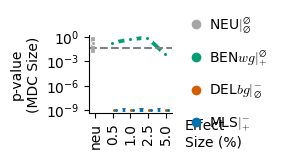

teeplots/2026-11-01-mls-indiv-spectra-fullgrid-fossils/hue=kind+kind=point+stat=mdc-duration+viz=catplot+what=mann-whitney+x=effect-size+y=effect-size-ps+ext=.pdf
teeplots/2026-11-01-mls-indiv-spectra-fullgrid-fossils/hue=kind+kind=point+stat=mdc-duration+viz=catplot+what=mann-whitney+x=effect-size+y=effect-size-ps+ext=.png


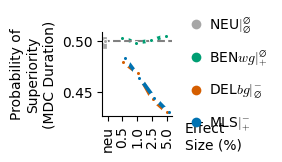

teeplots/2026-11-01-mls-indiv-spectra-fullgrid-fossils/hue=kind+kind=point+stat=mdc-duration+viz=catplot+what=mann-whitney+x=effect-size+y=p-value+ext=.pdf
teeplots/2026-11-01-mls-indiv-spectra-fullgrid-fossils/hue=kind+kind=point+stat=mdc-duration+viz=catplot+what=mann-whitney+x=effect-size+y=p-value+ext=.png


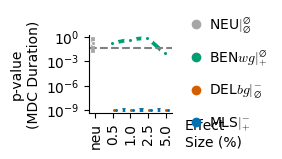

In [ ]:
for _stat, _df in mdc_tests.groupby("stat", sort=False):
    _df = _df.assign(
        p_value=lambda df: df["p_value"].fillna(1.0).clip(lower=1e-9),
    )
    for _y, _label in (
        ("effect_size_ps", "Probability of\nSuperiority"),
        ("p_value", "p-value"),
    ):
        with tp.teed(
            sns.catplot,
            data=_df,
            x="effect_size",
            y=_y,
            order=effect_size_order,
            hue="kind",
            hue_order=kind_order,
            palette=kind_palette,
            kind="point",
            errorbar=("pi", 100),
            dodge=0.3,
            height=1.5,
            aspect=1.3,
            log_scale=(False, _y == "p_value"),
            teeplot_outattrs={
                "stat": _stat.lower().replace(" ", "-"),
                "what": "mann-whitney",
            },
            teeplot_outexclude=[
                "palette",
                "hue_order",
                "dodge",
                "order",
                "log_scale",
            ],
            teeplot_show=True,
            teeplot_subdir=pathlib.Path(__file__).stem,
        ) as _g:
            gap_points(*_g.axes.flat, _g.legend)
            if _y == "p_value":
                _g.refline(y=ALPHA, color="gray", linestyle="--")
                # p = 1 at top, descending to the 1e-9 clip floor
                _g.set(
                    ylim=(10**-9.4, 10**0.2),
                    yticks=[1, 1e-3, 1e-6, 1e-9],
                )
            else:
                _g.refline(y=0.5, color="gray", linestyle="--")
            _g.set_axis_labels("", f"{_label}\n({_stat})")
            tilt_xticklabels(_g)
            corner_xlabel(_g, right_legend(_g))
        plt.close("all")

MLS and `DELbg` MDCs are smaller and shorter-lived than neutral MDCs at every effect size, increasingly so with effect size, and indistinguishable from each other.
`BENwg` MDCs are about the size and duration of neutral MDCs (probability of superiority within about 0.01 of 0.5), so these tests detect between-host cost but not within-host advantage.

## Gain and Selection Estimates

`alifestd_tgs_estimate_polars` fits each site separately, with the four neutral sites as the reference for gain ratios (each neutral site against the other three, leave-one-out).
Fits are run over all branches (allmdc) and over pendant (leaf) branches only (pendantmdc, with `episode_mask="is_leaf"`), each with raw branch lengths and with branch lengths calibrated against neutral sites' gains.
Calibration follows the estimator's documented example: all-branch fits calibrate within clade size classes, by neighborhoods of joint quantile bins of branch length, origin time, and survival duration; pendant fits calibrate by bins of branch length and origin time.
Loss rate is taken as 0.

Nested branches share leaves, so the likelihood is composite: the naive likelihood-ratio statistics (for selection = 0 and gain ratio = 1) are not calibrated as $\chi^2_1$, and are shown only as a relative measure of evidence.

In [ ]:
neutral_traits = [trait_names[_site] for _site in neutral_sites]
calibration_df = mark_calibration_columns(
    phylo, trait_names, neutral_traits
)

In [ ]:
estimates = fit_estimates(calibration_df, trait_names, neutral_traits)

allmdc raw: 61s
allmdc calibrated: 86s
pendantmdc raw: 23s
pendantmdc calibrated: 29s


In [ ]:
estimates_by_site = estimates.merge(site_info, on="trait")
# naive chi-squared p-values; the likelihood is composite, so these
# overstate the evidence
for _stat in ("selection", "gain_ratio"):
    estimates_by_site[f"{_stat}_p_naive"] = scipy_stats.chi2.sf(
        estimates_by_site[f"{_stat}_lrt_naive"].clip(lower=0), df=1
    )
# selection relative to the mean of the other neutral sites'
_neutral = estimates_by_site["kind"].str.startswith("NEU")
_grouped = estimates_by_site[_neutral].groupby(["method", "calibration"])
_sum = _grouped["selection"].transform("sum")
_count = _grouped["selection"].transform("size")
_ref = (
    estimates_by_site[_neutral]
    .groupby(["method", "calibration"])["selection"]
    .mean()
    .rename("neutral_selection_mean")
)
estimates_by_site = estimates_by_site.merge(
    _ref, on=["method", "calibration"]
)
estimates_by_site["relative_selection"] = (
    estimates_by_site["selection"]
    - estimates_by_site["neutral_selection_mean"]
)
# leave each neutral site out of its own reference
estimates_by_site.loc[_neutral.to_numpy(), "relative_selection"] = (
    estimates_by_site.loc[_neutral.to_numpy(), "selection"]
    - (_sum - estimates_by_site.loc[_neutral.to_numpy(), "selection"])
    / (_count - 1)
).to_numpy()
mo.Html(
    estimates_by_site.drop(columns=["neutral_selection_mean"]).to_html(
        float_format="{:.4g}".format
    ),
)

,num_leaves,num_trait_present,num_clades,num_clade_gains,trait,gain_rate,selection,gain_ratio,selection_lrt_naive,gain_ratio_lrt_naive,method,calibration,site,kind,effect_size,configured_gain_ratio,selection_p_naive,gain_ratio_p_naive,relative_selection
0,3936081,9840,3694647,1825,site0,1.736e-06,-0.0002059,1.626,827.8,810.4,allmdc,raw,0,BEN$\mathit{wg}|^{\varnothing}_{+}$,5.0,1.992,4.95e-182,3.018e-178,1.055e-05
1,3937422,7166,3694812,1236,site1,1.263e-06,-0.0002117,1.183,620.5,72.68,allmdc,raw,1,BEN$\mathit{wg}|^{\varnothing}_{+}$,2.5,1.389,5.693e-137,1.526e-17,4.723e-06
2,3938007,5912,3694897,986,site2,1.056e-06,-0.0002228,0.9894,551.8,0.2475,allmdc,raw,2,BEN$\mathit{wg}|^{\varnothing}_{+}$,1.0,1.136,4.996e-122,0.6189,-6.331e-06
3,3937802,5916,3694838,1060,site3,1.026e-06,-0.0001993,0.961,466.2,3.51,allmdc,raw,3,BEN$\mathit{wg}|^{\varnothing}_{+}$,0.5,1.065,2.152e-103,0.06101,1.714e-05
4,3940224,2544,3695180,20,site8,2.208e-06,-0.002822,2.068,2462,160,allmdc,raw,8,MLS$|^{-}_{+}$,5.0,1.992,0,1.126e-36,-0.002606
5,3940019,3004,3695175,120,site9,1.183e-06,-0.001047,1.108,1846,7.831,allmdc,raw,9,MLS$|^{-}_{+}$,2.5,1.389,0,0.005136,-0.0008302
6,3939527,4059,3695126,341,site10,1.029e-06,-0.000523,0.9637,1241,1.774,allmdc,raw,10,MLS$|^{-}_{+}$,1.0,1.136,8.147e-272,0.1829,-0.0003065
7,3938918,4740,3695064,615,site11,9.627e-07,-0.0003239,0.9017,781.4,18.18,allmdc,raw,11,MLS$|^{-}_{+}$,0.5,1.065,5.901e-172,2.014e-05,-0.0001075
8,3940243,1440,3695181,11,site12,1.238e-06,-0.002793,1.16,1459,3.685,allmdc,raw,12,DEL$\mathit{bg}|^{-}_{\varnothing}$,5.0,1,0,0.05489,-0.002577
9,3940078,2534,3695174,90,site13,1.059e-06,-0.001137,0.9921,1620,0.03601,allmdc,raw,13,DEL$\mathit{bg}|^{-}_{\varnothing}$,2.5,1,0,0.8495,-0.0009203


teeplots/2026-11-01-mls-indiv-spectra-fullgrid-fossils/calibration=raw+hue=kind+kind=point+method=allmdc+stat=gain-ratio+viz=catplot+x=effect-size+y=gain-ratio+ext=.pdf
teeplots/2026-11-01-mls-indiv-spectra-fullgrid-fossils/calibration=raw+hue=kind+kind=point+method=allmdc+stat=gain-ratio+viz=catplot+x=effect-size+y=gain-ratio+ext=.png


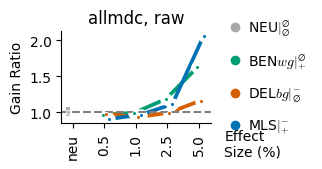

teeplots/2026-11-01-mls-indiv-spectra-fullgrid-fossils/calibration=raw+hue=kind+kind=point+method=allmdc+stat=gain-ratio+viz=catplot+x=effect-size+y=gain-ratio+yscale=log+ext=.pdf
teeplots/2026-11-01-mls-indiv-spectra-fullgrid-fossils/calibration=raw+hue=kind+kind=point+method=allmdc+stat=gain-ratio+viz=catplot+x=effect-size+y=gain-ratio+yscale=log+ext=.png


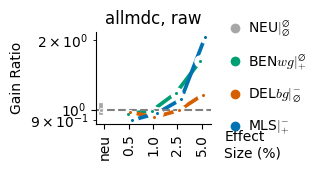

teeplots/2026-11-01-mls-indiv-spectra-fullgrid-fossils/calibration=raw+hue=kind+kind=point+method=allmdc+stat=selection+viz=catplot+x=effect-size+y=selection+ext=.pdf
teeplots/2026-11-01-mls-indiv-spectra-fullgrid-fossils/calibration=raw+hue=kind+kind=point+method=allmdc+stat=selection+viz=catplot+x=effect-size+y=selection+ext=.png


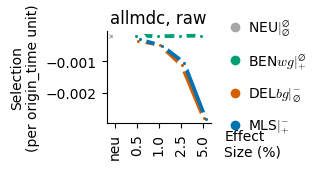

teeplots/2026-11-01-mls-indiv-spectra-fullgrid-fossils/calibration=raw+hue=kind+kind=point+method=allmdc+stat=relative-selection+viz=catplot+x=effect-size+y=relative-selection+ext=.pdf
teeplots/2026-11-01-mls-indiv-spectra-fullgrid-fossils/calibration=raw+hue=kind+kind=point+method=allmdc+stat=relative-selection+viz=catplot+x=effect-size+y=relative-selection+ext=.png


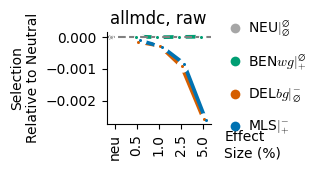

teeplots/2026-11-01-mls-indiv-spectra-fullgrid-fossils/calibration=calibrated+hue=kind+kind=point+method=allmdc+stat=gain-ratio+viz=catplot+x=effect-size+y=gain-ratio+ext=.pdf
teeplots/2026-11-01-mls-indiv-spectra-fullgrid-fossils/calibration=calibrated+hue=kind+kind=point+method=allmdc+stat=gain-ratio+viz=catplot+x=effect-size+y=gain-ratio+ext=.png


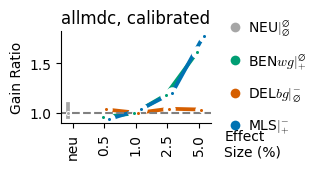

teeplots/2026-11-01-mls-indiv-spectra-fullgrid-fossils/calibration=calibrated+hue=kind+kind=point+method=allmdc+stat=gain-ratio+viz=catplot+x=effect-size+y=gain-ratio+yscale=log+ext=.pdf
teeplots/2026-11-01-mls-indiv-spectra-fullgrid-fossils/calibration=calibrated+hue=kind+kind=point+method=allmdc+stat=gain-ratio+viz=catplot+x=effect-size+y=gain-ratio+yscale=log+ext=.png


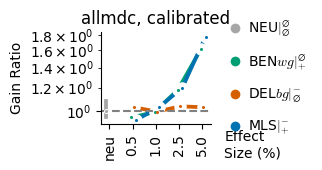

teeplots/2026-11-01-mls-indiv-spectra-fullgrid-fossils/calibration=calibrated+hue=kind+kind=point+method=allmdc+stat=selection+viz=catplot+x=effect-size+y=selection+ext=.pdf
teeplots/2026-11-01-mls-indiv-spectra-fullgrid-fossils/calibration=calibrated+hue=kind+kind=point+method=allmdc+stat=selection+viz=catplot+x=effect-size+y=selection+ext=.png


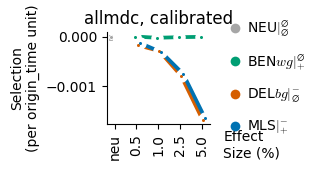

teeplots/2026-11-01-mls-indiv-spectra-fullgrid-fossils/calibration=calibrated+hue=kind+kind=point+method=allmdc+stat=relative-selection+viz=catplot+x=effect-size+y=relative-selection+ext=.pdf
teeplots/2026-11-01-mls-indiv-spectra-fullgrid-fossils/calibration=calibrated+hue=kind+kind=point+method=allmdc+stat=relative-selection+viz=catplot+x=effect-size+y=relative-selection+ext=.png


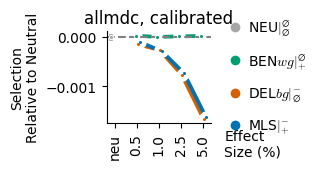

teeplots/2026-11-01-mls-indiv-spectra-fullgrid-fossils/calibration=raw+hue=kind+kind=point+method=pendantmdc+stat=gain-ratio+viz=catplot+x=effect-size+y=gain-ratio+ext=.pdf
teeplots/2026-11-01-mls-indiv-spectra-fullgrid-fossils/calibration=raw+hue=kind+kind=point+method=pendantmdc+stat=gain-ratio+viz=catplot+x=effect-size+y=gain-ratio+ext=.png


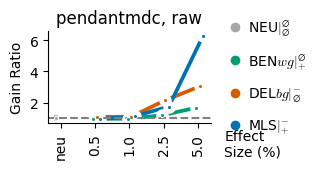

teeplots/2026-11-01-mls-indiv-spectra-fullgrid-fossils/calibration=raw+hue=kind+kind=point+method=pendantmdc+stat=gain-ratio+viz=catplot+x=effect-size+y=gain-ratio+yscale=log+ext=.pdf
teeplots/2026-11-01-mls-indiv-spectra-fullgrid-fossils/calibration=raw+hue=kind+kind=point+method=pendantmdc+stat=gain-ratio+viz=catplot+x=effect-size+y=gain-ratio+yscale=log+ext=.png


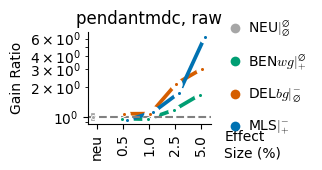

teeplots/2026-11-01-mls-indiv-spectra-fullgrid-fossils/calibration=raw+hue=kind+kind=point+method=pendantmdc+stat=selection+viz=catplot+x=effect-size+y=selection+ext=.pdf
teeplots/2026-11-01-mls-indiv-spectra-fullgrid-fossils/calibration=raw+hue=kind+kind=point+method=pendantmdc+stat=selection+viz=catplot+x=effect-size+y=selection+ext=.png


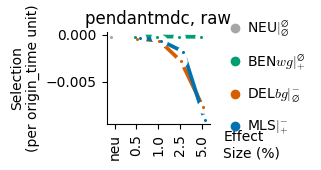

teeplots/2026-11-01-mls-indiv-spectra-fullgrid-fossils/calibration=raw+hue=kind+kind=point+method=pendantmdc+stat=relative-selection+viz=catplot+x=effect-size+y=relative-selection+ext=.pdf
teeplots/2026-11-01-mls-indiv-spectra-fullgrid-fossils/calibration=raw+hue=kind+kind=point+method=pendantmdc+stat=relative-selection+viz=catplot+x=effect-size+y=relative-selection+ext=.png


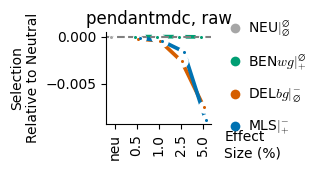

teeplots/2026-11-01-mls-indiv-spectra-fullgrid-fossils/calibration=calibrated+hue=kind+kind=point+method=pendantmdc+stat=gain-ratio+viz=catplot+x=effect-size+y=gain-ratio+ext=.pdf
teeplots/2026-11-01-mls-indiv-spectra-fullgrid-fossils/calibration=calibrated+hue=kind+kind=point+method=pendantmdc+stat=gain-ratio+viz=catplot+x=effect-size+y=gain-ratio+ext=.png


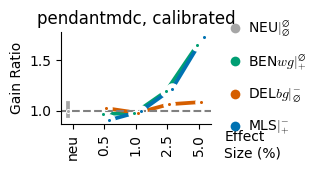

teeplots/2026-11-01-mls-indiv-spectra-fullgrid-fossils/calibration=calibrated+hue=kind+kind=point+method=pendantmdc+stat=gain-ratio+viz=catplot+x=effect-size+y=gain-ratio+yscale=log+ext=.pdf
teeplots/2026-11-01-mls-indiv-spectra-fullgrid-fossils/calibration=calibrated+hue=kind+kind=point+method=pendantmdc+stat=gain-ratio+viz=catplot+x=effect-size+y=gain-ratio+yscale=log+ext=.png


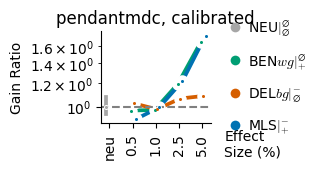

teeplots/2026-11-01-mls-indiv-spectra-fullgrid-fossils/calibration=calibrated+hue=kind+kind=point+method=pendantmdc+stat=selection+viz=catplot+x=effect-size+y=selection+ext=.pdf
teeplots/2026-11-01-mls-indiv-spectra-fullgrid-fossils/calibration=calibrated+hue=kind+kind=point+method=pendantmdc+stat=selection+viz=catplot+x=effect-size+y=selection+ext=.png


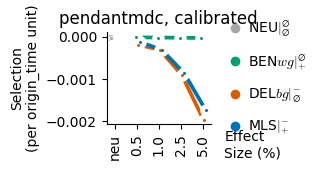

teeplots/2026-11-01-mls-indiv-spectra-fullgrid-fossils/calibration=calibrated+hue=kind+kind=point+method=pendantmdc+stat=relative-selection+viz=catplot+x=effect-size+y=relative-selection+ext=.pdf
teeplots/2026-11-01-mls-indiv-spectra-fullgrid-fossils/calibration=calibrated+hue=kind+kind=point+method=pendantmdc+stat=relative-selection+viz=catplot+x=effect-size+y=relative-selection+ext=.png


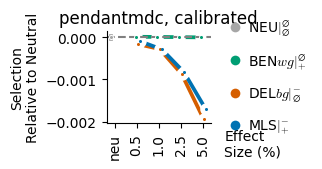

In [ ]:
# gain ratios also on a log scale, as they can span orders of magnitude
_plots = [
    ("gain_ratio", "Gain Ratio", False),
    ("gain_ratio", "Gain Ratio", True),
    ("selection", "Selection\n(per origin_time unit)", False),
    ("relative_selection", "Selection\nRelative to Neutral", False),
]
for (_method, _calibration), _df in estimates_by_site.groupby(
    ["method", "calibration"], sort=False
):
    for _stat, _label, _log in _plots:
        with tp.teed(
            sns.catplot,
            data=_df,
            x="effect_size",
            y=_stat,
            order=effect_size_order,
            hue="kind",
            hue_order=kind_order,
            palette=kind_palette,
            kind="point",
            errorbar=("pi", 100),
            dodge=0.3,
            height=1.8,
            aspect=1.3,
            log_scale=(False, _log),
            teeplot_outattrs={
                "method": _method,
                "calibration": _calibration,
                "stat": _stat.replace("_", "-"),
                **({"yscale": "log"} if _log else {}),
            },
            teeplot_outexclude=[
                "palette",
                "hue_order",
                "dodge",
                "order",
                "log_scale",
            ],
            teeplot_show=True,
            teeplot_subdir=pathlib.Path(__file__).stem,
        ) as _g:
            gap_points(*_g.axes.flat, _g.legend)
            if _stat == "gain_ratio":
                _g.refline(y=1, color="gray", linestyle="--")
            elif _stat == "relative_selection":
                _g.refline(y=0, color="gray", linestyle="--")
            _g.set_axis_labels("", _label)
            _g.axes.flat[0].set_title(f"{_method}, {_calibration}")
            tilt_xticklabels(_g)
            corner_xlabel(_g, right_legend(_g))
        plt.close("all")

teeplots/2026-11-01-mls-indiv-spectra-fullgrid-fossils/col=calibration+hue=kind+method=allmdc+viz=relplot+x=configured-gain-ratio+y=gain-ratio+ext=.pdf
teeplots/2026-11-01-mls-indiv-spectra-fullgrid-fossils/col=calibration+hue=kind+method=allmdc+viz=relplot+x=configured-gain-ratio+y=gain-ratio+ext=.png


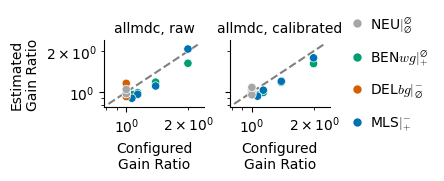

teeplots/2026-11-01-mls-indiv-spectra-fullgrid-fossils/col=calibration+hue=kind+method=pendantmdc+viz=relplot+x=configured-gain-ratio+y=gain-ratio+ext=.pdf
teeplots/2026-11-01-mls-indiv-spectra-fullgrid-fossils/col=calibration+hue=kind+method=pendantmdc+viz=relplot+x=configured-gain-ratio+y=gain-ratio+ext=.png


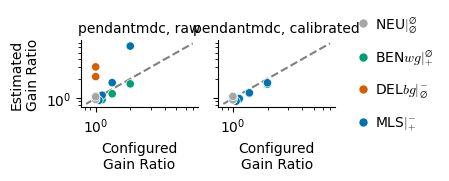

In [ ]:
for _method, _df in estimates_by_site.groupby("method", sort=False):
    with tp.teed(
        sns.relplot,
        data=_df,
        x="configured_gain_ratio",
        y="gain_ratio",
        hue="kind",
        hue_order=kind_order,
        palette=kind_palette,
        col="calibration",
        col_order=["raw", "calibrated"],
        height=1.8,
        aspect=1.0,
        teeplot_outattrs={"method": _method},
        teeplot_outexclude=["palette", "hue_order", "col_order"],
        teeplot_show=True,
        teeplot_subdir=pathlib.Path(__file__).stem,
    ) as _g:
        _values = _df[["configured_gain_ratio", "gain_ratio"]]
        _values = _values[_values > 0]
        _lo, _hi = _values.min().min(), _values.max().max()
        for _ax in _g.axes.flat:
            _ax.plot(
                [_lo / 1.1, _hi * 1.1],
                [_lo / 1.1, _hi * 1.1],
                color="gray",
                linestyle="--",
                zorder=0,
            )
            # log axes, as gain ratios can span orders of magnitude
            _ax.set_xscale("log")
            _ax.set_yscale("log")
        _g.set_axis_labels(
            "Configured\nGain Ratio", "Estimated\nGain Ratio"
        )
        _g.set_titles(col_template=f"{_method}, {{col_name}}")
        right_legend(_g)
    plt.close("all")

teeplots/2026-11-01-mls-indiv-spectra-fullgrid-fossils/calibration=raw+col=test+hue=kind+kind=point+method=allmdc+viz=catplot+what=lrt+x=effect-size+y=lrt+ext=.pdf
teeplots/2026-11-01-mls-indiv-spectra-fullgrid-fossils/calibration=raw+col=test+hue=kind+kind=point+method=allmdc+viz=catplot+what=lrt+x=effect-size+y=lrt+ext=.png


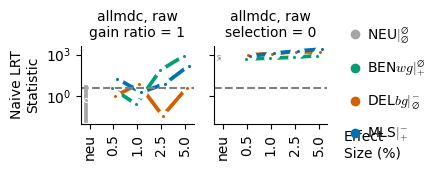

teeplots/2026-11-01-mls-indiv-spectra-fullgrid-fossils/calibration=calibrated+col=test+hue=kind+kind=point+method=allmdc+viz=catplot+what=lrt+x=effect-size+y=lrt+ext=.pdf
teeplots/2026-11-01-mls-indiv-spectra-fullgrid-fossils/calibration=calibrated+col=test+hue=kind+kind=point+method=allmdc+viz=catplot+what=lrt+x=effect-size+y=lrt+ext=.png


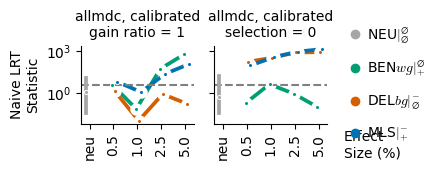

teeplots/2026-11-01-mls-indiv-spectra-fullgrid-fossils/calibration=raw+col=test+hue=kind+kind=point+method=pendantmdc+viz=catplot+what=lrt+x=effect-size+y=lrt+ext=.pdf
teeplots/2026-11-01-mls-indiv-spectra-fullgrid-fossils/calibration=raw+col=test+hue=kind+kind=point+method=pendantmdc+viz=catplot+what=lrt+x=effect-size+y=lrt+ext=.png


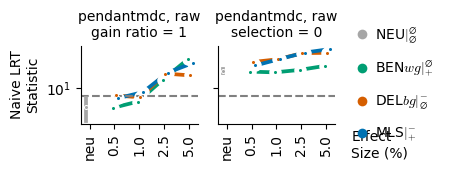

teeplots/2026-11-01-mls-indiv-spectra-fullgrid-fossils/calibration=calibrated+col=test+hue=kind+kind=point+method=pendantmdc+viz=catplot+what=lrt+x=effect-size+y=lrt+ext=.pdf
teeplots/2026-11-01-mls-indiv-spectra-fullgrid-fossils/calibration=calibrated+col=test+hue=kind+kind=point+method=pendantmdc+viz=catplot+what=lrt+x=effect-size+y=lrt+ext=.png


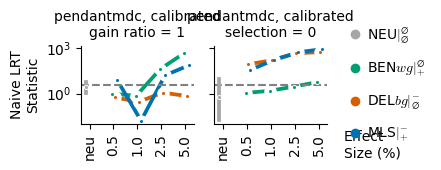

In [ ]:
_df = estimates_by_site.melt(
    id_vars=["method", "calibration", "kind", "effect_size"],
    value_vars=["selection_lrt_naive", "gain_ratio_lrt_naive"],
    var_name="test",
    value_name="lrt",
).assign(
    test=lambda df: df["test"].map(
        {
            "selection_lrt_naive": "selection = 0",
            "gain_ratio_lrt_naive": "gain ratio = 1",
        },
    ),
    lrt=lambda df: df["lrt"].clip(lower=1e-2),
)
for (_method, _calibration), _part in _df.groupby(
    ["method", "calibration"], sort=False
):
    with tp.teed(
        sns.catplot,
        data=_part,
        x="effect_size",
        y="lrt",
        order=effect_size_order,
        hue="kind",
        hue_order=kind_order,
        palette=kind_palette,
        col="test",
        col_order=["gain ratio = 1", "selection = 0"],
        kind="point",
        errorbar=("pi", 100),
        dodge=0.3,
        height=1.8,
        aspect=1.0,
        log_scale=(False, True),
        teeplot_outattrs={
            "method": _method,
            "calibration": _calibration,
            "what": "lrt",
        },
        teeplot_outexclude=[
            "palette",
            "hue_order",
            "col_order",
            "dodge",
            "order",
            "log_scale",
        ],
        teeplot_show=True,
        teeplot_subdir=pathlib.Path(__file__).stem,
    ) as _g:
        gap_points(*_g.axes.flat, _g.legend)
        # naive chi-squared critical value at alpha
        _g.refline(
            y=scipy_stats.chi2.isf(ALPHA, df=1),
            color="gray",
            linestyle="--",
        )
        _g.set_axis_labels("", "Naive LRT\nStatistic")
        _g.set_titles(
            col_template=f"{_method}, {_calibration}\n{{col_name}}"
        )
        tilt_xticklabels(_g)
        corner_xlabel(_g, right_legend(_g))
    plt.close("all")

teeplots/2026-11-01-mls-indiv-spectra-fullgrid-fossils/col=calibration+hue=kind+stat=gain-ratio+viz=relplot+x=gain-ratio-pendantmdc+y=gain-ratio-allmdc+ext=.pdf
teeplots/2026-11-01-mls-indiv-spectra-fullgrid-fossils/col=calibration+hue=kind+stat=gain-ratio+viz=relplot+x=gain-ratio-pendantmdc+y=gain-ratio-allmdc+ext=.png


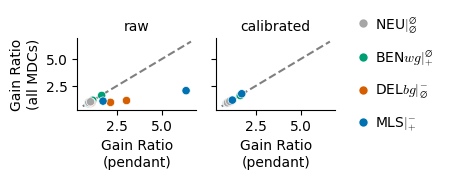

teeplots/2026-11-01-mls-indiv-spectra-fullgrid-fossils/col=calibration+hue=kind+stat=selection+viz=relplot+x=selection-pendantmdc+y=selection-allmdc+ext=.pdf
teeplots/2026-11-01-mls-indiv-spectra-fullgrid-fossils/col=calibration+hue=kind+stat=selection+viz=relplot+x=selection-pendantmdc+y=selection-allmdc+ext=.png


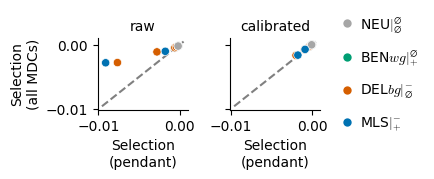

In [ ]:
_wide = estimates_by_site.pivot_table(
    index=["trait", "kind", "effect_size", "calibration"],
    columns="method",
    values=["gain_ratio", "selection"],
)
_wide.columns = [f"{_stat} {_m}" for _stat, _m in _wide.columns]
_wide = _wide.reset_index()
for _stat in ("gain_ratio", "selection"):
    with tp.teed(
        sns.relplot,
        data=_wide,
        x=f"{_stat} pendantmdc",
        y=f"{_stat} allmdc",
        hue="kind",
        hue_order=kind_order,
        palette=kind_palette,
        col="calibration",
        col_order=["raw", "calibrated"],
        height=1.8,
        aspect=1.0,
        teeplot_outattrs={"stat": _stat.replace("_", "-")},
        teeplot_outexclude=["palette", "hue_order", "col_order"],
        teeplot_show=True,
        teeplot_subdir=pathlib.Path(__file__).stem,
    ) as _g:
        _all = _wide[[f"{_stat} pendantmdc", f"{_stat} allmdc"]]
        _lo, _hi = _all.min().min(), _all.max().max()
        _pad = 0.05 * (_hi - _lo)
        for _ax in _g.axes.flat:
            _ax.plot(
                [_lo - _pad, _hi + _pad],
                [_lo - _pad, _hi + _pad],
                color="gray",
                linestyle="--",
                zorder=0,
            )
        _name = _stat.replace("_", " ").title()
        _g.set_axis_labels(f"{_name}\n(pendant)", f"{_name}\n(all MDCs)")
        _g.set_titles(col_template="{col_name}")
        right_legend(_g)
    plt.close("all")

## Fit Diagnostics

These plots compare observed trait gains with those expected under the calibrated allmdc fit, recomputed from the estimator's own exposure episodes, calibrated branch lengths, and survival times (via `phyloframe.legacy._impl`).
Branches whose parent lacks a trait are grouped by clade size class (the calibration partitions; 1 for pendant branches) and binned by calibrated branch length, into bins of equal total length (so, about equal expected neutral gains).

Two fits are compared:

- **with survival time**, the allmdc model, and
- **without survival time**, the same model refit with every branch's survival time set to 0, which expects the same gain share for a branch of a given length whatever its clade size.

For reference, the neutral expectation is the mean neutral gain rate (for a neutral site, the other three's) times calibrated length, and the trait's own expectation is its fitted gain rate times calibrated length, i.e., without selection.
Error bars are 95% Poisson intervals.

In [ ]:
diagnostic_fits, fit_diagnostics = compute_fit_diagnostics(
    calibration_df, trait_names, neutral_traits
)
diagnostic_fits = diagnostic_fits.merge(site_info, on="trait")
fit_diagnostics = fit_diagnostics.merge(site_info, on="trait")
mo.Html(
    diagnostic_fits.to_html(float_format="{:.4g}".format),
)

,gain_rate,selection,gain_ratio,selection_coef_lrt_naive,gain_ratio_lrt_naive,trait,fit,neutral_gain_rate,site,kind,effect_size,configured_gain_ratio
0,1.156e-06,-2.468e-06,1.617,NaN,NaN,site0,with survival time,7.151e-07,0,BEN$\mathit{wg}|^{\varnothing}_{+}$,5.0,1.992
1,8.436e-07,-8.967e-06,1.18,NaN,NaN,site1,with survival time,7.151e-07,1,BEN$\mathit{wg}|^{\varnothing}_{+}$,2.5,1.389
2,7.105e-07,-2.169e-05,0.9936,NaN,NaN,site2,with survival time,7.151e-07,2,BEN$\mathit{wg}|^{\varnothing}_{+}$,1.0,1.136
3,6.816e-07,4.399e-06,0.9532,NaN,NaN,site3,with survival time,7.151e-07,3,BEN$\mathit{wg}|^{\varnothing}_{+}$,0.5,1.065
4,1.274e-06,-0.001635,1.781,NaN,NaN,site8,with survival time,7.151e-07,8,MLS$|^{-}_{+}$,5.0,1.992
5,8.579e-07,-0.0007497,1.2,NaN,NaN,site9,with survival time,7.151e-07,9,MLS$|^{-}_{+}$,2.5,1.389
6,7.386e-07,-0.0003129,1.033,NaN,NaN,site10,with survival time,7.151e-07,10,MLS$|^{-}_{+}$,1.0,1.136
7,6.678e-07,-0.000124,0.9339,NaN,NaN,site11,with survival time,7.151e-07,11,MLS$|^{-}_{+}$,0.5,1.065
8,7.372e-07,-0.00168,1.031,NaN,NaN,site12,with survival time,7.151e-07,12,DEL$\mathit{bg}|^{-}_{\varnothing}$,5.0,1
9,7.429e-07,-0.0007836,1.039,NaN,NaN,site13,with survival time,7.151e-07,13,DEL$\mathit{bg}|^{-}_{\varnothing}$,2.5,1


In [ ]:
def poisson_interval(count, alpha=0.05):
    """Exact (Garwood) Poisson confidence interval for an observed count."""
    count = np.asarray(count, dtype=float)
    lower = np.where(
        count > 0, scipy_stats.chi2.ppf(alpha / 2, 2 * count) / 2, 0.0
    )
    upper = scipy_stats.chi2.ppf(1 - alpha / 2, 2 * (count + 1)) / 2
    return lower, upper

In [ ]:
def shade_palette(kind_key, num):
    """Shades of a site class's ETI color, from dark to light."""
    _dark, __, _light = ETI_PALETTE[kind_key]
    return sns.blend_palette([_dark, _light], max(num, 2))[:num]

In [ ]:
# one row per site class, one column per effect size (largest first),
# or per neutral site
_kind_keys = dict(zip(kind_order, ["neutral", "BENwg", "DELbg", "MLS"]))
panel_layout = []
for _kind in kind_order:
    _sites = site_info[site_info["kind"] == _kind]
    if _kind.startswith("NEU"):
        _sites = _sites.sort_values("site")
    else:
        _sites = _sites.sort_values(
            "effect_size", key=lambda x: -x.astype(float)
        )
    panel_layout.append(
        [
            (
                _row["trait"],
                _kind,
                _kind_keys[_kind],
                (
                    f"NEU site {_row['site']}"
                    if _kind.startswith("NEU")
                    else f"s = {_row['effect_size']}%"
                ),
            )
            for __, _row in _sites.iterrows()
        ],
    )

teeplots/2026-11-01-mls-indiv-spectra-fullgrid-fossils/fit=calibrated-allmdc+viz=obs-exp-by-size+ext=.pdf


teeplots/2026-11-01-mls-indiv-spectra-fullgrid-fossils/fit=calibrated-allmdc+viz=obs-exp-by-size+ext=.png


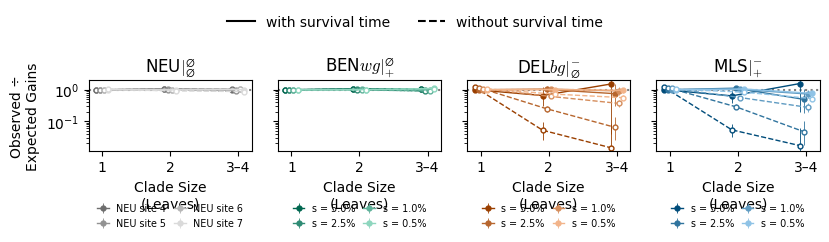

In [ ]:
# first three size partitions: pendants, 2 tips, and 3-4 tips (larger
# clades hold few gains)
_sizes = (
    fit_diagnostics.sort_values("size_partition")["clade_size"]
    .drop_duplicates()
    .tolist()[:3]
)
_agg = (
    fit_diagnostics[fit_diagnostics["clade_size"].isin(_sizes)]
    .groupby(["trait", "clade_size"], sort=False)[
        [
            "num_successes",
            "expected with survival time",
            "expected without survival time",
        ]
    ]
    .sum()
    .reset_index()
)

def obs_exp_by_size(data):
    _fig, _axes = plt.subplots(
        1,
        len(panel_layout),
        figsize=(2.1 * len(panel_layout), 3.1),
        sharey=True,
    )
    for _ax, _row in zip(_axes, panel_layout):
        _colors = shade_palette(_row[0][2], len(_row))
        for _j, ((_trait, _kind, __, _label), _color) in enumerate(
            zip(_row, _colors)
        ):
            _d = (
                data[data["trait"] == _trait]
                .set_index("clade_size")
                .reindex(_sizes)
            )
            _x = np.arange(len(_sizes)) + (_j - 1.5) * 0.06
            _obs = _d["num_successes"].fillna(0).to_numpy()
            _lo, _hi = poisson_interval(_obs)
            for _fit, _style, _marker in (
                ("with survival time", "-", "o"),
                ("without survival time", "--", "o"),
            ):
                _exp = _d[f"expected {_fit}"].to_numpy()
                _ratio = np.maximum(_obs, 0.5) / _exp
                _ax.errorbar(
                    _x,
                    _ratio,
                    yerr=[_ratio - _lo / _exp, _hi / _exp - _ratio],
                    color=_color,
                    linestyle=_style,
                    marker=_marker,
                    markersize=3.5,
                    markerfacecolor=(_color if _style == "-" else "white"),
                    linewidth=1,
                    elinewidth=0.6,
                    label=_label if _style == "-" else None,
                )
        _ax.axhline(1, color="gray", linestyle=":", zorder=0)
        _ax.set_yscale("log")
        _ax.set_xticks(range(len(_sizes)), _sizes)
        _ax.set_title(_row[0][1])
        _ax.set_xlabel("Clade Size\n(Leaves)")
        _ax.legend(
            loc="upper center",
            bbox_to_anchor=(0.5, -0.62),
            ncol=2,
            fontsize="x-small",
            frameon=False,
            handlelength=1.2,
            columnspacing=0.8,
        )
    _axes[0].set_ylabel("Observed ÷\nExpected Gains")
    _fig.legend(
        [
            plt.Line2D([], [], color="black", linestyle="-"),
            plt.Line2D([], [], color="black", linestyle="--"),
        ],
        ["with survival time", "without survival time"],
        loc="lower center",
        bbox_to_anchor=(0.5, 1.0),
        ncol=2,
        frameon=False,
    )
    _fig.tight_layout()

tp.tee(
    obs_exp_by_size,
    data=_agg,
    teeplot_outattrs={"fit": "calibrated-allmdc"},
    teeplot_show=True,
    teeplot_subdir=pathlib.Path(__file__).stem,
)
plt.close("all")

In [ ]:
_num_bins = 20
_sizes = (
    fit_diagnostics.sort_values("size_partition")["clade_size"]
    .drop_duplicates()
    .tolist()[:3]
)
_cols = [
    "num_trials",
    "num_successes",
    "expected with survival time",
    "expected without survival time",
]
_binned = []
for _group, _df in [
    ("all branches", fit_diagnostics),
    *(
        (_size, fit_diagnostics[fit_diagnostics["clade_size"] == _size])
        for _size in _sizes
    ),
]:
    for _trait, _part in _df.groupby("trait"):
        _part = _part.sort_values("length")
        # bins of equal total calibrated length (so, about equal
        # expected neutral gains), rather than equal branch counts,
        # which would crowd short, uninformative branches into many
        # noisy bins
        _weight = _part["num_trials"] * _part["length"]
        _cum = _weight.cumsum() / _weight.sum()
        _bin = np.minimum((_cum * _num_bins).astype(int), _num_bins - 1)
        _agg = (
            _part.assign(
                weighted_length=_part["length"] * _part["num_trials"],
                bin=_bin.to_numpy(),
            )
            .groupby("bin")[[*_cols, "weighted_length"]]
            .sum()
        )
        _agg["length"] = _agg["weighted_length"] / _agg["num_trials"]
        _binned.append(
            _agg.drop(columns="weighted_length")
            .reset_index()
            .assign(trait=_trait, group=_group),
        )
length_bins = pd.concat(_binned, ignore_index=True)
_lo, _hi = poisson_interval(length_bins["num_successes"])
length_bins["share"] = (
    length_bins["num_successes"] / length_bins["num_trials"]
)
length_bins["share_lo"] = _lo / length_bins["num_trials"]
length_bins["share_hi"] = _hi / length_bins["num_trials"]
for _fit in ("with survival time", "without survival time"):
    length_bins[f"share {_fit}"] = (
        length_bins[f"expected {_fit}"] / length_bins["num_trials"]
    )
_rates = diagnostic_fits[
    diagnostic_fits["fit"] == "with survival time"
].set_index("trait")
length_bins["share neutral"] = length_bins["length"] * length_bins[
    "trait"
].map(_rates["neutral_gain_rate"])
length_bins["share own rate"] = length_bins["length"] * length_bins[
    "trait"
].map(_rates["gain_rate"])
length_bin_groups = ["all branches", *_sizes]

teeplots/2026-11-01-mls-indiv-spectra-fullgrid-fossils/axes=linear+branches=all+viz=gain-share-by-length+y=share+ext=.pdf


teeplots/2026-11-01-mls-indiv-spectra-fullgrid-fossils/axes=linear+branches=all+viz=gain-share-by-length+y=share+ext=.png


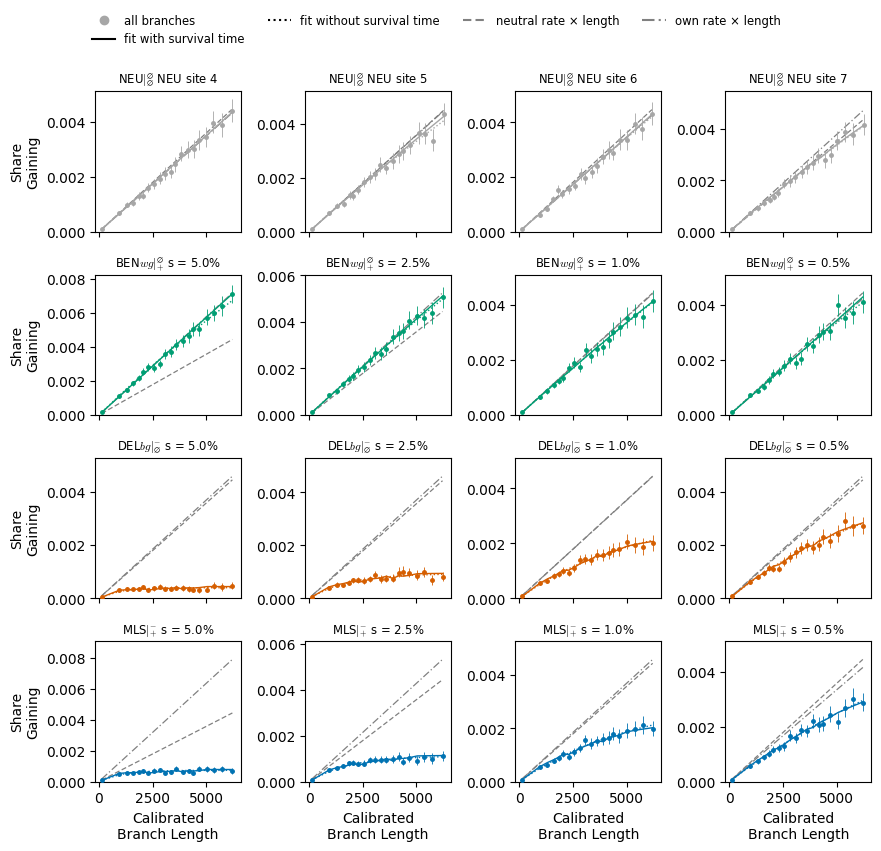

teeplots/2026-11-01-mls-indiv-spectra-fullgrid-fossils/axes=linear+branches=all+viz=gain-share-by-length+y=relative-to-neutral+ext=.pdf


teeplots/2026-11-01-mls-indiv-spectra-fullgrid-fossils/axes=linear+branches=all+viz=gain-share-by-length+y=relative-to-neutral+ext=.png


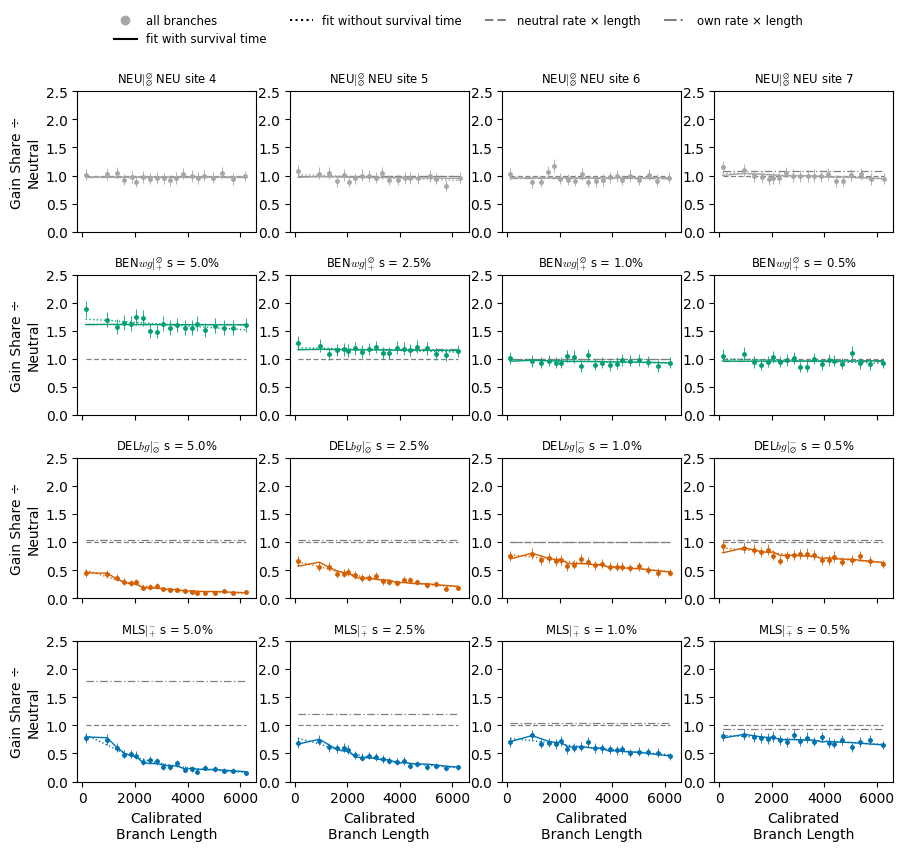

teeplots/2026-11-01-mls-indiv-spectra-fullgrid-fossils/axes=log+branches=all+viz=gain-share-by-length+y=share+ext=.pdf


teeplots/2026-11-01-mls-indiv-spectra-fullgrid-fossils/axes=log+branches=all+viz=gain-share-by-length+y=share+ext=.png


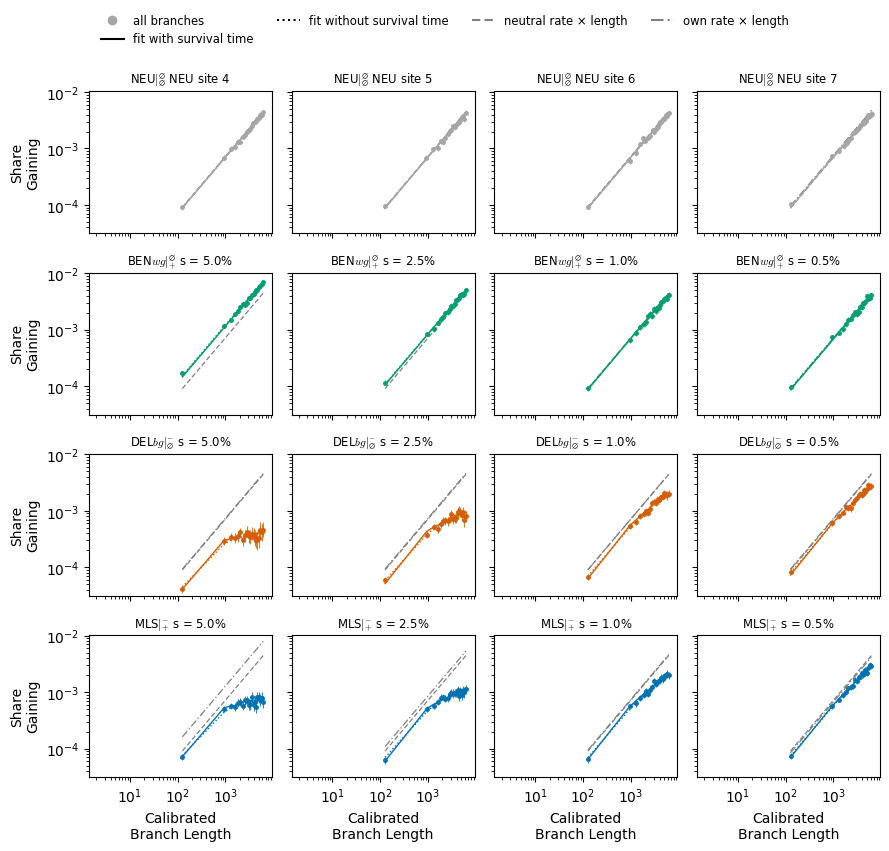

teeplots/2026-11-01-mls-indiv-spectra-fullgrid-fossils/axes=linear+branches=by-clade-size+viz=gain-share-by-length+y=share+ext=.pdf


teeplots/2026-11-01-mls-indiv-spectra-fullgrid-fossils/axes=linear+branches=by-clade-size+viz=gain-share-by-length+y=share+ext=.png


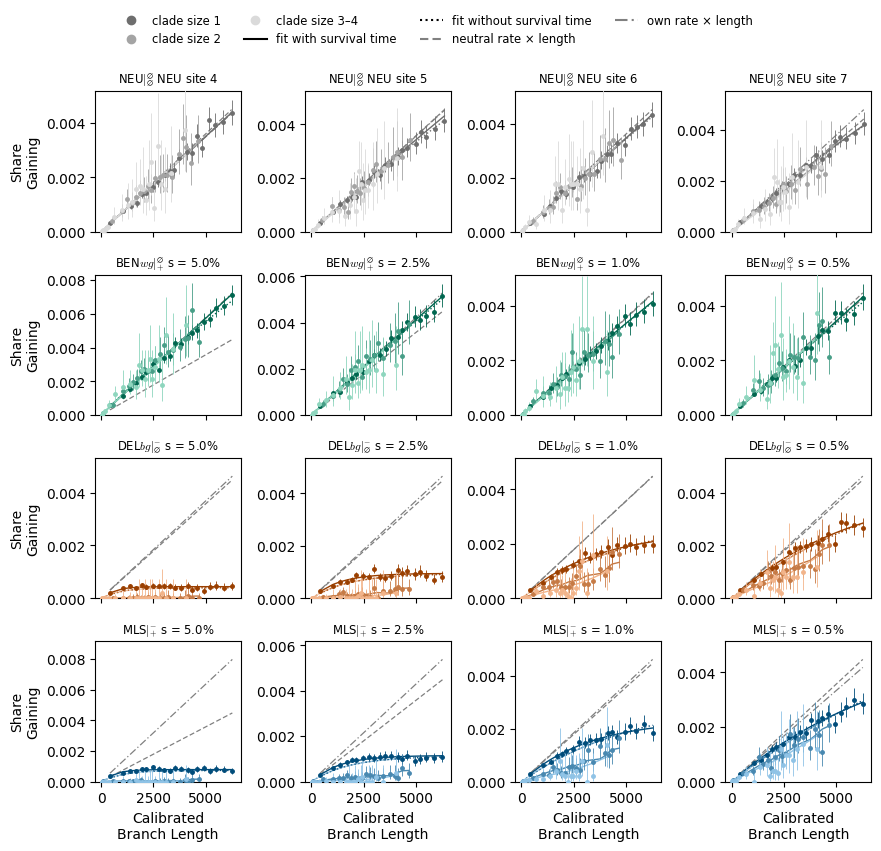

teeplots/2026-11-01-mls-indiv-spectra-fullgrid-fossils/axes=linear+branches=by-clade-size+viz=gain-share-by-length+y=relative-to-neutral+ext=.pdf


teeplots/2026-11-01-mls-indiv-spectra-fullgrid-fossils/axes=linear+branches=by-clade-size+viz=gain-share-by-length+y=relative-to-neutral+ext=.png


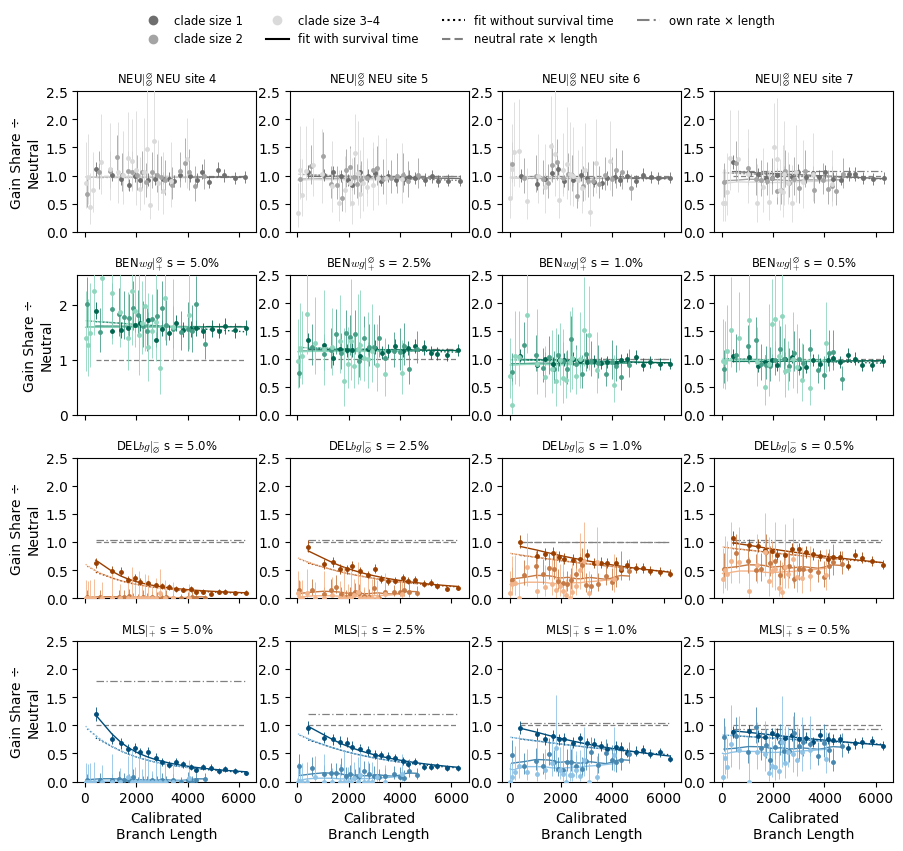

In [ ]:
def gain_share_by_length(data, groups, relative, log_axes):
    _shares = [
        "share",
        "share_lo",
        "share_hi",
        "share with survival time",
        "share without survival time",
        "share neutral",
        "share own rate",
    ]
    if relative:
        data = data.assign(
            **{_c: data[_c] / data["share neutral"] for _c in _shares},
        )
    _fig, _axes = plt.subplots(
        len(panel_layout),
        max(map(len, panel_layout)),
        figsize=(9, 8),
        sharex=True,
        # log axes share a scale; linear axes fit each panel, as strong
        # effects (e.g., large gain ratios) would flatten the others
        sharey=log_axes,
        squeeze=False,
    )
    for _axrow, _row in zip(_axes, panel_layout):
        for _ax, (_trait, _kind, _key, _label) in zip(_axrow, _row):
            _colors = shade_palette(_key, len(groups))
            if len(groups) == 1:
                _colors = [ETI_PALETTE[_key][1]]
            _d = data[data["trait"] == _trait]
            _first = _d[_d["group"] == groups[0]]
            for _col, _style in (
                ("share neutral", (0, (4, 2))),
                ("share own rate", (0, (6, 2, 1, 2))),
            ):
                _ax.plot(
                    _first["length"],
                    _first[_col],
                    color="gray",
                    linestyle=_style,
                    linewidth=0.9,
                    zorder=1,
                )
            for _group, _color in zip(groups, _colors):
                _g = _d[_d["group"] == _group]
                _ax.errorbar(
                    _g["length"],
                    _g["share"],
                    yerr=[
                        _g["share"] - _g["share_lo"],
                        _g["share_hi"] - _g["share"],
                    ],
                    color=_color,
                    linestyle="none",
                    marker="o",
                    markersize=2.5,
                    elinewidth=0.6,
                    zorder=3,
                )
                for _fit, _style in (
                    ("with survival time", "-"),
                    ("without survival time", ":"),
                ):
                    _ax.plot(
                        _g["length"],
                        _g[f"share {_fit}"],
                        color=_color,
                        linestyle=_style,
                        linewidth=1,
                        zorder=2,
                    )
            _ax.set_title(f"{_kind} {_label}", fontsize="small")
            if log_axes:
                _ax.set_xscale("log")
                _ax.set_yscale("log")
            else:
                # fit each panel to its fitted and reference lines and
                # observed bins, not to the wide intervals of bins with
                # few expected gains (e.g., short branches)
                _shown = _d[_d["group"].isin(groups)]
                _lines = _shown[
                    [
                        "share with survival time",
                        "share without survival time",
                        "share neutral",
                        "share own rate",
                    ]
                ].to_numpy()
                _top = 1.15 * max(
                    np.nanmax(_lines),
                    np.nanquantile(_shown["share"], 0.95),
                )
                _ax.set_ylim(0, max(_top, 2.5) if relative else _top)
    for _ax in _axes[-1]:
        _ax.set_xlabel("Calibrated\nBranch Length")
    for _ax in _axes[:, 0]:
        _ax.set_ylabel(
            "Gain Share ÷\nNeutral" if relative else "Share\nGaining"
        )
    _handles = [
        *(
            plt.Line2D([], [], color=_c, marker="o", linestyle="none")
            for _c in (
                shade_palette("neutral", len(groups))
                if len(groups) > 1
                else [ETI_PALETTE["neutral"][1]]
            )
        ),
        plt.Line2D([], [], color="black", linestyle="-"),
        plt.Line2D([], [], color="black", linestyle=":"),
        plt.Line2D([], [], color="gray", linestyle=(0, (4, 2))),
        plt.Line2D([], [], color="gray", linestyle=(0, (6, 2, 1, 2))),
    ]
    _labels = [
        *(
            f"clade size {_g}" if _g != "all branches" else _g
            for _g in groups
        ),
        "fit with survival time",
        "fit without survival time",
        "neutral rate × length",
        "own rate × length",
    ]
    _fig.legend(
        _handles,
        _labels,
        loc="lower center",
        bbox_to_anchor=(0.5, 1.0),
        ncol=4,
        frameon=False,
        fontsize="small",
    )
    _fig.tight_layout()

for _groups, _relative, _log in (
    (["all branches"], False, False),
    (["all branches"], True, False),
    (["all branches"], False, True),
    (length_bin_groups[1:], False, False),
    (length_bin_groups[1:], True, False),
):
    tp.tee(
        gain_share_by_length,
        data=length_bins,
        groups=_groups,
        relative=_relative,
        log_axes=_log,
        teeplot_outattrs={
            "branches": (
                "all" if _groups == ["all branches"] else "by-clade-size"
            ),
            "y": "relative-to-neutral" if _relative else "share",
            "axes": "log" if _log else "linear",
        },
        teeplot_outexclude=["groups", "relative", "log_axes"],
        teeplot_show=True,
        teeplot_subdir=pathlib.Path(__file__).stem,
    )
    plt.close("all")

With survival time, observed gains match the fit's expectation across clade sizes for every site class.
Without survival time, MLS and `DELbg` sites' multi-leaf MDCs fall far short of expectation, increasingly so with effect size, so the survival term is what captures their between-host cost.
For these costly sites, the share of branches gaining the trait levels off with branch length, well below both the neutral expectation and their own gain rate times length.

### Notes

- With calibrated branch lengths, neutral and `BENwg` sites' selection estimates are near 0, while MLS and `DELbg` sites' are negative, about $-1.5 \times 10^{-3}$ per `origin_time` unit at $s = 5\%$, falling roughly in proportion to effect size.
- MLS and `DELbg` sites' estimates are about equal, so the between-host (transmission) cost dominates selection; the within-host advantage shows up in the gain ratio instead.
- With raw branch lengths, neutral and `BENwg` sites' selection estimates are about $-2 \times 10^{-4}$ rather than 0, and MLS and `DELbg` sites' are more negative than calibrated ones (about $-2.8 \times 10^{-3}$ at $s = 5\%$).
- Estimated gain ratios rise with configured within-host gain ratio for `BENwg` and MLS sites, but fall short of it: about 1.5–1.8 at $s = 5\%$ (configured 1.99), about 1.2 at $s = 2.5\%$ (1.39), and about 1 at $s \leq 1\%$ (1.14 and 1.07).
- `DELbg` and neutral sites' calibrated gain ratios are near 1 (0.95–1.08).